# neuralCAD-Edit

neuralCAD-Edit is stored as a mongita database containing metadata and filepaths, which point to objects (images, .step etc.) in the file tree. 

This notebook contains some ways to visualise the data. We recommend always accessing the data through the database, and the access patterns used here should give you and idea about how to do this.

### Imports and config

Make sure the paths in the config are correct

In [2]:
import os
import os.path as osp
import sys
module_path = os.path.abspath(os.path.join('../..'))
sys.path.append(module_path)
from src.utils.db import DatabaseManager
from src.utils.process_config import load_config
from IPython.display import display
from PIL import Image as PILImage, ImageDraw, ImageFont
import shutil

config_path = os.path.join(module_path, 'src', 'config', 'edit_192_external.json')

class Args:
    def __init__(self, config):
        self.config = config
args = Args(config=config_path)
config = load_config(args.config)
dbm = DatabaseManager(config)
print("Database manager initialized from config:", config_path)
dbm.print_db_schema_counts()


Database manager initialized from config: c:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\src\config\edit_192_external.json
Collection: users, Count: 22
Collection: breps, Count: 288
Collection: edits, Count: 240
Collection: requests, Count: 48
Collection: ratings, Count: 2001


### Function defs

Just run. You can collapse to get it out of the way.

In [3]:
def display_images_side_by_side(image_paths, new_height=512, labels=None, n_horizontal=4):
    """
    Display a list of local image paths side by side with optional labels above each image.
    If more images are provided than the n_horizontal limit, they will wrap to the next line.

    Args:
        image_paths (list): List of file paths to images
        new_height (int): Height to resize images to
        labels (list, optional): List of text labels to display above each image
        n_horizontal (int): Maximum number of images per row
    """
    
    # Load and resize images
    images = []
    for img_path in image_paths:
        if os.path.exists(img_path):
            try:
                img = PILImage.open(img_path)
                # Calculate new width to maintain aspect ratio
                width_ratio = new_height / img.height
                new_width = int(img.width * width_ratio)
                img = img.resize((new_width, new_height))
                images.append(img)
            except Exception as e:
                print(f"Error loading image {img_path}: {e}")
    
    if not images:
        print("No valid images found to display")
        return
    
    # Calculate grid dimensions
    n_rows = (len(images) + n_horizontal - 1) // n_horizontal  # Ceiling division
    
    # Group images into rows
    image_rows = []
    label_rows = []
    
    for row_idx in range(n_rows):
        start_idx = row_idx * n_horizontal
        end_idx = min(start_idx + n_horizontal, len(images))
        
        row_images = images[start_idx:end_idx]
        row_labels = labels[start_idx:end_idx] if labels else None
        
        image_rows.append(row_images)
        label_rows.append(row_labels)
    
    # Calculate dimensions for the combined image
    label_height = 30 if labels else 0
    row_height = new_height + label_height
    
    # Find the maximum width needed (widest row)
    max_row_width = 0
    for row_images in image_rows:
        row_width = sum(img.width for img in row_images)
        max_row_width = max(max_row_width, row_width)
    
    total_height = row_height * n_rows
    
    # Create the combined image
    combined_image = PILImage.new('RGB', (max_row_width, total_height), color=(255, 255, 255))
    draw = ImageDraw.Draw(combined_image)
    
    try:
        font = ImageFont.truetype("Arial", 14)
    except IOError:
        font = ImageFont.load_default()
    
    # Process each row
    for row_idx, (row_images, row_labels) in enumerate(zip(image_rows, label_rows)):
        current_y = row_idx * row_height
        current_x = 0
        
        for i, img in enumerate(row_images):
            # Paste image
            combined_image.paste(img, (current_x, current_y + label_height))
            
            # Add label if provided
            if row_labels and i < len(row_labels):
                text = str(row_labels[i])
                text_width = draw.textlength(text, font=font)
                text_x = current_x + (img.width - text_width) // 2
                text_y = current_y + 5
                draw.text((text_x, text_y), text, fill=(0, 0, 0), font=font)
            
            current_x += img.width
    
    # Display the combined image
    display(combined_image)

def display_request_info(dbm, request_id):
    request = dbm.requests.find_one({"_id": request_id})
    if request_id is None:
        print(f"No request found with ID: {request_id}")
        return
    
    print("Request details:")
    print(f"Request ID: {request_id}")
    print(f"Keys: {list(request.keys())}")

    print()
    print("Brep:")
    breps = dbm.breps.find_one({"_id": request["brep_start"]})
    for key, value in breps.items():
        if value:
            if len(str(value)) > 500:
                value = '...'
            print(f"{key}: {value}")

    print()
    print("User details:")
    user = dbm.users.find_one({"_id": request["user"]})
    for key, value in user.items():
        if value:
            print(f"{key}: {value}")

    # show the instruction text
    print()
    instruction_text = request.get("text")
    if instruction_text:
        print("Instruction text:")
        print(instruction_text)
    else:
        print("No instruction text found for this request.")

def display_edit_info(dbm, edit_id, n_to_display=4):
    edit = dbm.edits.find_one({"_id": edit_id})
    if edit_id is None:
        print(f"No edit found with ID: {edit_id}")
        return
    print("Edit details:")
    print(f"Edit ID: {edit_id}")
    print(f"Keys: {list(edit.keys())}")

    print()
    print("Events")
    print(f"Number of events: {len(edit['events'])}")
    # pick n_to_display uniformly from the events
    if len(edit['events']) > n_to_display:
        step = len(edit['events']) // n_to_display
        events_to_display = edit['events'][::step][:n_to_display]
    else:
        events_to_display = edit['events']
    for event in events_to_display:
        print(event)

    print()
    print("brep end:")
    breps = dbm.breps.find_one({"_id": edit["brep_end"]})
    for key, value in breps.items():
        if value:
            if len(str(value)) > 500:
                value = '...'
            print(f"{key}: {value}")

    # show the toprightiso image of the brep end
    brep_images = dbm.get_brep_images(edit["brep_end"], views=["toprightiso"], format=["jpg", "png"])
    if brep_images:
        brep_image_path = os.path.join(dbm.root_dir, brep_images[0])
        display_images_side_by_side([brep_image_path])

    print()
    print("Frames:")
    frames_dir = os.path.join(dbm.root_dir, edit["frames_dir"])
    if os.path.exists(frames_dir):
        print(f"Frames directory found at: {frames_dir}")
        frames = os.listdir(frames_dir)
        frames.sort()
        display_images_side_by_side([os.path.join(frames_dir, f) for f in frames])
    else:
        print(f"Frames directory not found at: {frames_dir}")

def display_request_and_edits(dbm, request_id, output_dir=None, views=["toprightiso", "sketch", "render"], n_horizontal=4, height=384, models=[]):
    request = dbm.requests.find_one({"_id": request_id})
    edits = dbm.edits.find({"request": request_id})

    request_id = request["_id"]
    print(f"Request ID: {request_id}")
    user_2_img = {}
    for edit in edits:
        brep = dbm.breps.find_one({"_id": edit["brep_end"]})
        brep_id = brep["_id"]
        brep_img = dbm.get_brep_images(brep_id, views=views)
        if brep_img:
            brep_img = brep_img[0]
        else:
            continue
        brep_img = os.path.join(dbm.root_dir, brep_img)

        user = dbm.users.find_one({"_id": edit["user"]})

        if edit["user"] == request["user"]:
            display_user = "Human GT"
            # user_2_img["Human GT"] = brep_img
        elif user["is_human"]:
            display_user = "Human Other"
            # user_2_img["Human Other"] = brep_img
        else:
            display_user = user["_id"]
            # user_2_img[user["_id"]] = brep_img
        
        if len(models) > 0 and display_user not in models:
            continue


        user_2_img[display_user] = brep_img
        print(f"Edit ID: {edit['_id']}, User: {user['_id']}, BRep Image: {brep_img}")

    # display the request instruction text
    instruction_text = request.get("text")
    if instruction_text:
        print("Instruction text:")
        print(instruction_text)

    # display the request brep images
    brep_start = dbm.breps.find_one({"_id": request["brep_start"]})
    if brep_start:
        request_images = dbm.get_brep_images(brep_start["_id"], views=views, format=["jpg", "png"])
        
        request_images = [os.path.join(dbm.root_dir, img) for img in request_images]
        display_images_side_by_side(
            request_images,
            labels=[""] * len(request_images),
            new_height=height
        )
        if output_dir:
            for idx, img_path in enumerate(request_images):
                basename = os.path.basename(img_path)
                output_folder = os.path.join(output_dir, request_id)
                os.makedirs(output_folder, exist_ok=True)
                output_path = os.path.join(output_folder, basename)
                print(img_path, "->", output_path)
                shutil.copy(img_path, output_path)

    # sort the user_2_img dictionary by user name
    user_2_img = dict(sorted(user_2_img.items(), key=lambda item: item[0]))


    # if a list of models is provided, filter the user_2_img to only include those models (if they exist)
    if models:
        user_2_img = {user: img for user, img in user_2_img.items() if user in models}



    labels, images = [], []
    for user, img in user_2_img.items():
        labels.append(user)
        images.append(img)
    display_images_side_by_side(images, labels=labels, n_horizontal=n_horizontal, new_height=height)
    if output_dir:
        for img_path, user in zip(images, labels):
            basename = os.path.basename(img_path)
            output_folder = os.path.join(output_dir, request_id, user)
            os.makedirs(output_folder, exist_ok=True)
            output_path = os.path.join(output_folder, basename)
            print(img_path, "->", output_path)
            shutil.copy(img_path, output_path)


### Display all information about a single request
Here, we find a request from the database, which is from an medium difficuly draw-static request on a parametric assembly task.


In [4]:
request_ids = dbm.requests.find({"modality": "text", "difficulty": "medium", "assembly": True, "parametric": True})
request_ids = [request["_id"] for request in request_ids]

display_request_info(dbm, request_ids[0] if request_ids else None)

Request details:
Request ID: SUJ2G2UMJQR7PMBX_1759203664.9815512
Keys: ['_id', 'user', 'difficulty', 'brep_start', 'start_time', 'end_time', 'text', 'events', 'frames_dir', 'filename', 'request_type', 'prompt', 'instructions', 'modality', 'assembly', 'parametric', 'source', 'filename_cleaned', '30_720_audio']

Brep:
_id: SUJ2G2UMJQR7PMBX_1759203719.3361144
user: SUJ2G2UMJQR7PMBX
end_time: 1759203719.3361144
jpg: ['breps/SUJ2G2UMJQR7PMBX_1759203719.3361144_top.jpg', 'breps/SUJ2G2UMJQR7PMBX_1759203719.3361144_toprightiso.jpg', 'breps/SUJ2G2UMJQR7PMBX_1759203719.3361144_left.jpg', 'breps/SUJ2G2UMJQR7PMBX_1759203719.3361144_front.jpg', 'breps/SUJ2G2UMJQR7PMBX_1759203719.3361144_right.jpg', 'breps/SUJ2G2UMJQR7PMBX_1759203719.3361144_back.jpg', 'breps/SUJ2G2UMJQR7PMBX_1759203719.3361144_bottom.jpg']
f3d: ['breps/SUJ2G2UMJQR7PMBX_1759203719.3361144.f3d']
stl: ['breps/SUJ2G2UMJQR7PMBX_1759203719.3361144.stl']
step: ['breps/SUJ2G2UMJQR7PMBX_1759203719.3361144.step']
smt: ['breps/SUJ2G2UMJQR7PMB

### Display all information about a single edit

Here, we take a request, and find an edit which corresponds to that request.

Edit details:
Edit ID: SUJ2G2UMJQR7PMBX_1759203978.2858508
Keys: ['_id', 'request', 'brep_end', 'user', 'start_time', 'end_time', 'events', 'frames_dir', 'filename', 'token_counts', 'completion', 'prompt_completion']

Events
Number of events: 59
{'event': 'commandStarting', 'commandId': 'SketchCreate', 'commandName': 'Create Sketch', 'timestamp': 1759203982.320642}
{'event': 'activeSelectionChanged', 'entityType': 'adsk::fusion::SketchLine', 'bboxMin': [0.0, -16.827499389648438, 0.0], 'bboxMax': [0.0, -13.65250015258789, 0.0], 'area': None, 'centroid': None, 'timestamp': 1759204021.061446}
{'event': 'commandStarting', 'commandId': 'CommitCommand', 'commandName': 'OK', 'timestamp': 1759204066.743789}
{'event': 'commandStarting', 'commandId': 'CommitCommand', 'commandName': 'OK', 'timestamp': 1759204154.332875}

brep end:
_id: SUJ2G2UMJQR7PMBX_1759204204.9140851
user: SUJ2G2UMJQR7PMBX
end_time: 1759204204.9140851
jpg: ['breps/SUJ2G2UMJQR7PMBX_1759204204.9140851_top.jpg', 'breps/SUJ2G2UMJ

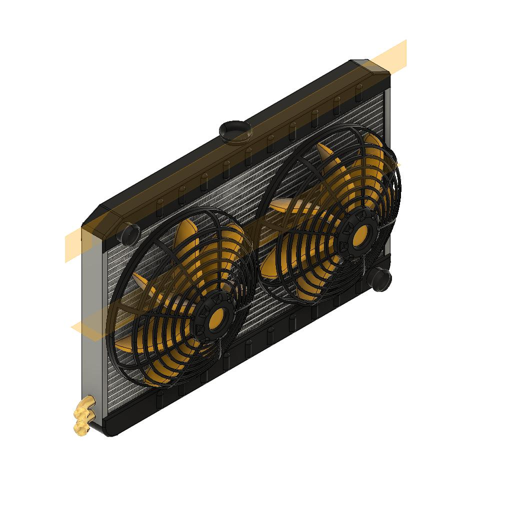


Frames:
Frames directory not found at: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\frames/SUJ2G2UMJQR7PMBX_1759203978.2858508


In [5]:
request_ids = dbm.requests.find({"modality": "text", "difficulty": "medium", "assembly": True, "parametric": True})
request_ids = [request["_id"] for request in request_ids]

edit_ids = dbm.edits.find({"request": {"$in": request_ids}})
edit_ids = [edit["_id"] for edit in edit_ids]

display_edit_info(dbm, edit_ids[0])

### Display all requests and the output of different users/AIs

Requests are shown below. If an AI did not produce a valid CAD model, then nothing is shown.

Found 48 requests
Request ID: 3YH2WFSRM22W7DKT_1769174947.8063738
Edit ID: 3YH2WFSRM22W7DKT_1769175814.6305332, User: 3YH2WFSRM22W7DKT, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/3YH2WFSRM22W7DKT_1769175834.340082_toprightiso.jpg
Edit ID: 4S7JQK6ZQMAD25GL_1770179400.0607848, User: 4S7JQK6ZQMAD25GL, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4S7JQK6ZQMAD25GL_1770179410.510611_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771138136.369163, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771138834.8028932_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771472970.8893702.
No images found for format ['jpg', 'png'] in brep gemini-3-pro_cadquery-script_1771540576.7753952.
Instruction text:
Mirror the 

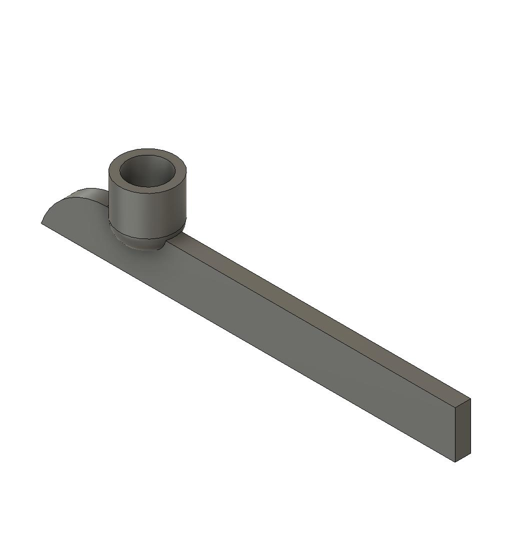

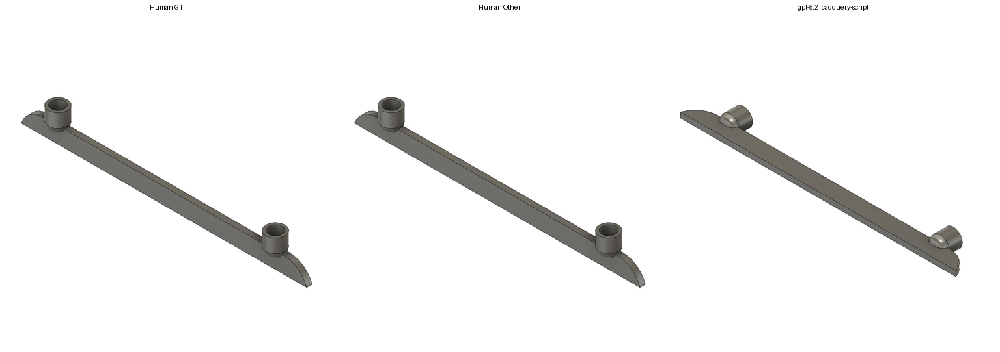

Request ID: 3YH2WFSRM22W7DKT_1769175216.745646
Edit ID: 3YH2WFSRM22W7DKT_1769175875.921942, User: 3YH2WFSRM22W7DKT, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/3YH2WFSRM22W7DKT_1769176057.004533_toprightiso.jpg
Edit ID: 4S7JQK6ZQMAD25GL_1770186381.9168189, User: 4S7JQK6ZQMAD25GL, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4S7JQK6ZQMAD25GL_1770186722.92591_toprightiso.jpg
Edit ID: claude-sonnet-4.5_cadquery-script_1771030347.1762218, User: claude-sonnet-4.5_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/claude-sonnet-4.5_cadquery-script_1771030783.999739_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771140208.913985, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771141424

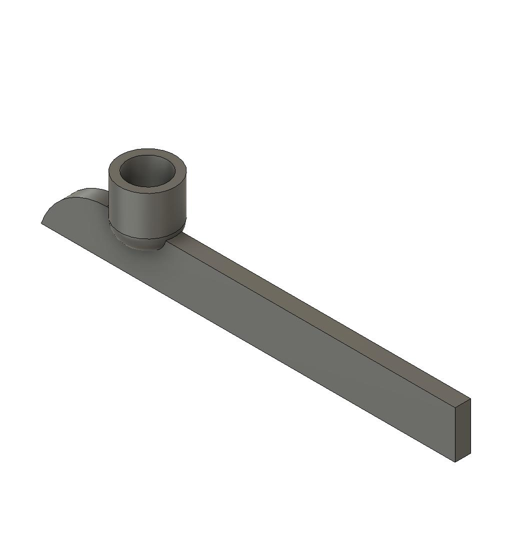

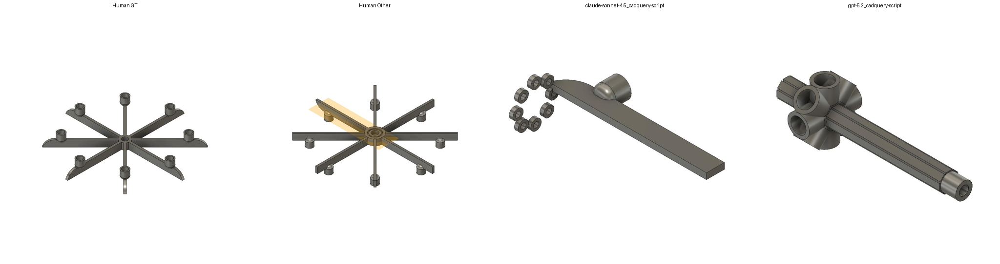

Request ID: 3YH2WFSRM22W7DKT_1769175629.871246
Edit ID: 3YH2WFSRM22W7DKT_1769176084.485151, User: 3YH2WFSRM22W7DKT, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/3YH2WFSRM22W7DKT_1769176584.041443_toprightiso.jpg
Edit ID: 4S7JQK6ZQMAD25GL_1770179694.309611, User: 4S7JQK6ZQMAD25GL, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4S7JQK6ZQMAD25GL_1770180042.853617_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771138834.803841, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771140208.912489_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771473521.805957.
Edit ID: gemini-3-pro_cadquery-script_1771540576.778962, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autod

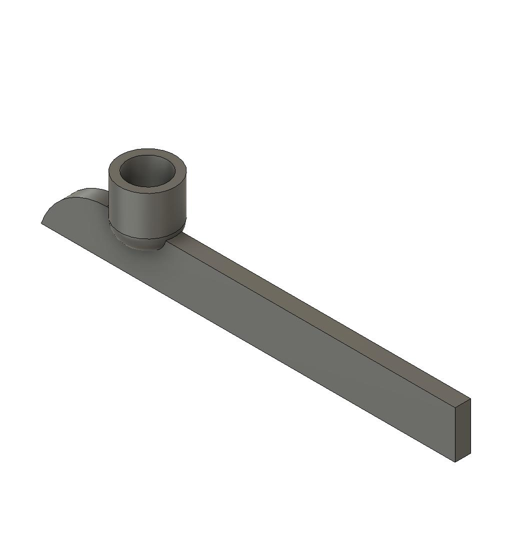

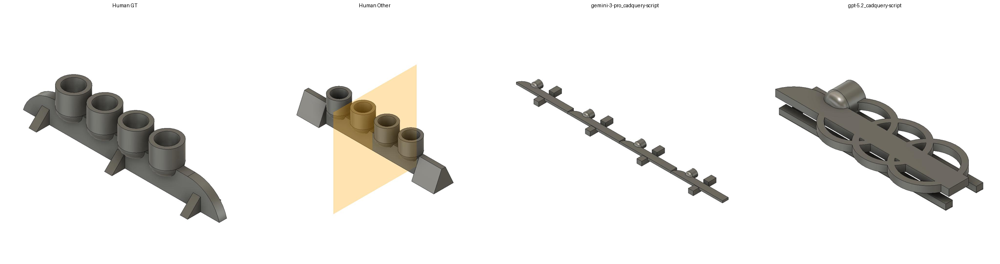

Request ID: 3YH2WFSRM22W7DKT_1769176912.388391
Edit ID: SUJ2G2UMJQR7PMBX_1770201864.006989, User: SUJ2G2UMJQR7PMBX, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/SUJ2G2UMJQR7PMBX_1770201876.485464_toprightiso.jpg
Edit ID: 3YH2WFSRM22W7DKT_1769177594.7748768, User: 3YH2WFSRM22W7DKT, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/3YH2WFSRM22W7DKT_1769177662.483708_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771055489.715673, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771056330.0941188_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771454120.552751.
No images found for format ['jpg', 'png'] in brep gemini-3-pro_cadquery-script_1771625948.6627588.
Instruction text:
Add cylindrical pin into the bea

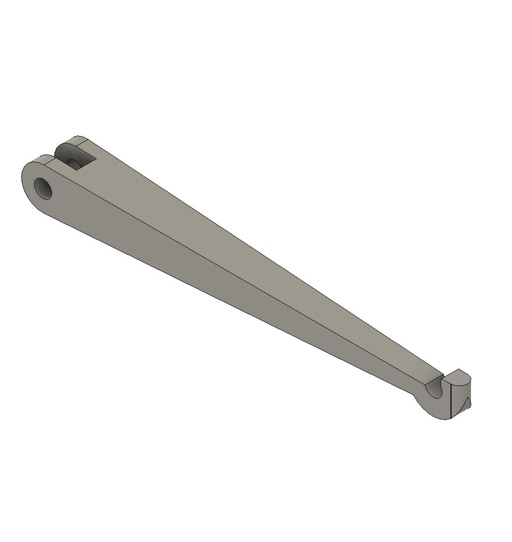

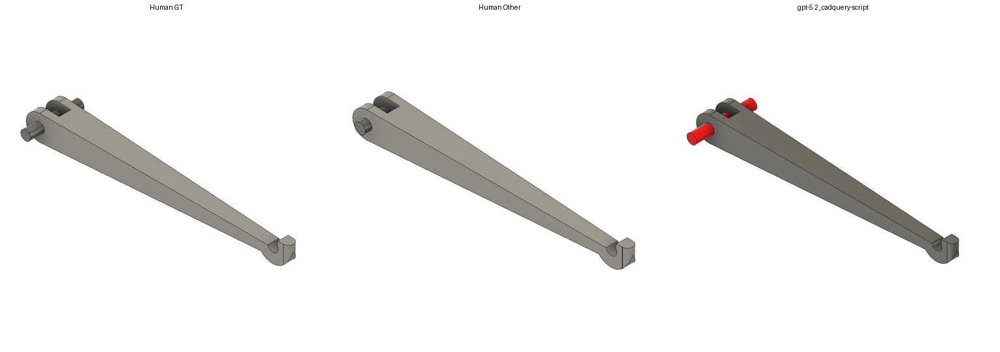

Request ID: 3YH2WFSRM22W7DKT_1769177020.525719
Edit ID: SUJ2G2UMJQR7PMBX_1770180440.757531, User: SUJ2G2UMJQR7PMBX, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/SUJ2G2UMJQR7PMBX_1770181134.858264_toprightiso.jpg
Edit ID: 3YH2WFSRM22W7DKT_1769177709.2119339, User: 3YH2WFSRM22W7DKT, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/3YH2WFSRM22W7DKT_1769177940.308554_toprightiso.jpg
Edit ID: claude-sonnet-4.5_cadquery-script_1771003032.3209531, User: claude-sonnet-4.5_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/claude-sonnet-4.5_cadquery-script_1771003363.1284611_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771057445.668232, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_17710576

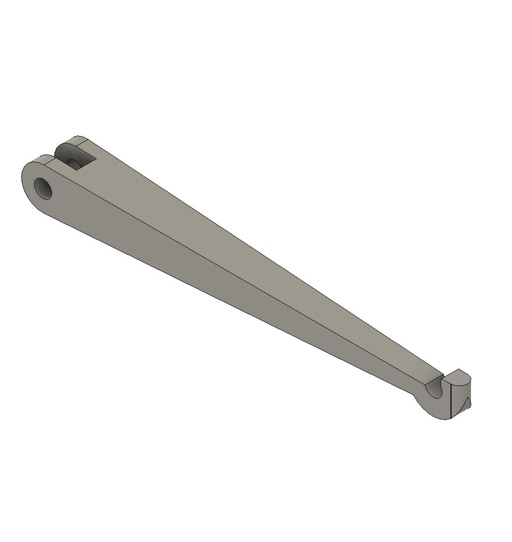

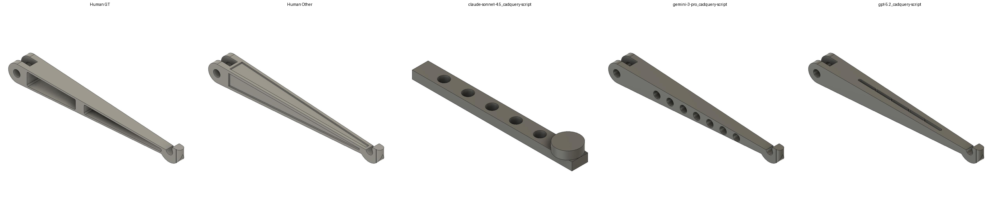

Request ID: 3YH2WFSRM22W7DKT_1769177116.6129558
Edit ID: SUJ2G2UMJQR7PMBX_1770201243.64847, User: SUJ2G2UMJQR7PMBX, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/SUJ2G2UMJQR7PMBX_1770201493.8573298_toprightiso.jpg
Edit ID: 3YH2WFSRM22W7DKT_1769178032.1216419, User: 3YH2WFSRM22W7DKT, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/3YH2WFSRM22W7DKT_1769178755.560677_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771056330.0951822, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771057445.667226_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771491522.64626.
No images found for format ['jpg', 'png'] in brep gemini-3-pro_cadquery-script_1771626787.8955882.
Instruction text:
Design simple locking mechanism 

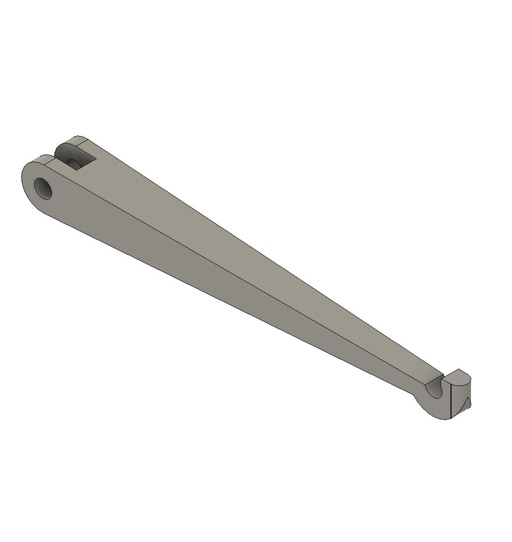

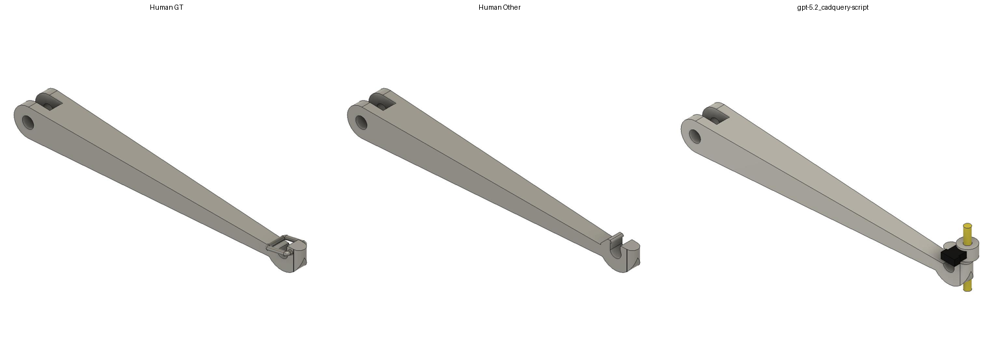

Request ID: 3YH2WFSRM22W7DKT_1769773134.1453462
Edit ID: DYP2J9CYL7X46RLQ_1770179104.747509, User: DYP2J9CYL7X46RLQ, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/DYP2J9CYL7X46RLQ_1770179259.833334_toprightiso.jpg
Edit ID: 3YH2WFSRM22W7DKT_1769775552.978208, User: 3YH2WFSRM22W7DKT, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/3YH2WFSRM22W7DKT_1769775710.843203_toprightiso.jpg
Edit ID: claude-sonnet-4.5_cadquery-script_1771042157.6776152, User: claude-sonnet-4.5_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/claude-sonnet-4.5_cadquery-script_1771042793.932074_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771171306.78898, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771172420

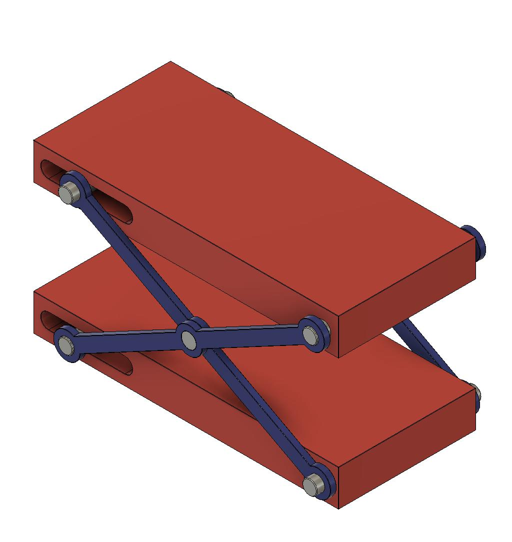

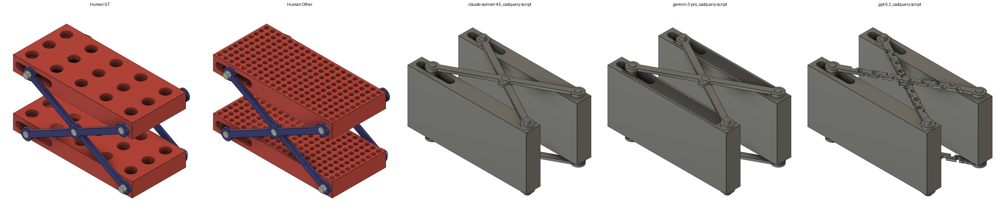

Request ID: 3YH2WFSRM22W7DKT_1769773335.525203
Edit ID: DYP2J9CYL7X46RLQ_1770186958.083383, User: DYP2J9CYL7X46RLQ, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/DYP2J9CYL7X46RLQ_1770187029.628212_toprightiso.jpg
Edit ID: 3YH2WFSRM22W7DKT_1769776718.7657201, User: 3YH2WFSRM22W7DKT, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/3YH2WFSRM22W7DKT_1769776990.4257011_toprightiso.jpg
Edit ID: claude-sonnet-4.5_cadquery-script_1771043329.849885, User: claude-sonnet-4.5_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/claude-sonnet-4.5_cadquery-script_1771043690.891785_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771173598.737011, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_177117381

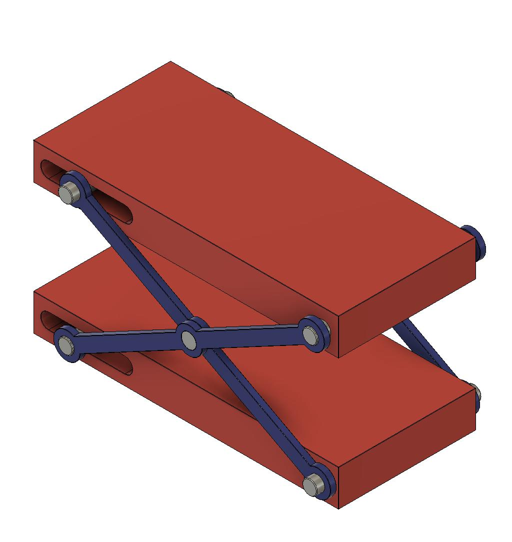

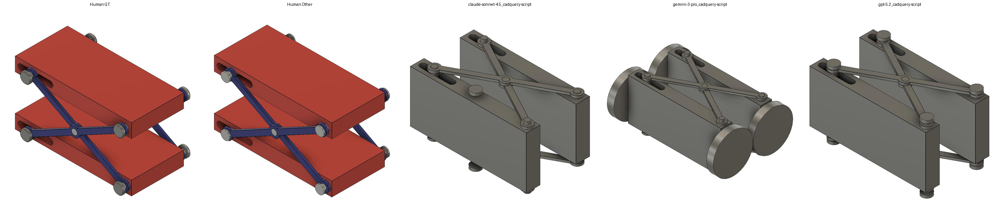

Request ID: 3YH2WFSRM22W7DKT_1769773481.491738
Edit ID: DYP2J9CYL7X46RLQ_1770181595.4399328, User: DYP2J9CYL7X46RLQ, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/DYP2J9CYL7X46RLQ_1770182226.242806_toprightiso.jpg
Edit ID: 3YH2WFSRM22W7DKT_1769778096.052108, User: 3YH2WFSRM22W7DKT, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/3YH2WFSRM22W7DKT_1769778363.131156_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771172420.6204631, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771173598.736021_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771480731.887428.
No images found for format ['jpg', 'png'] in brep gemini-3-pro_cadquery-script_1771640709.138819.
Instruction text:
Change the shape of the profile o

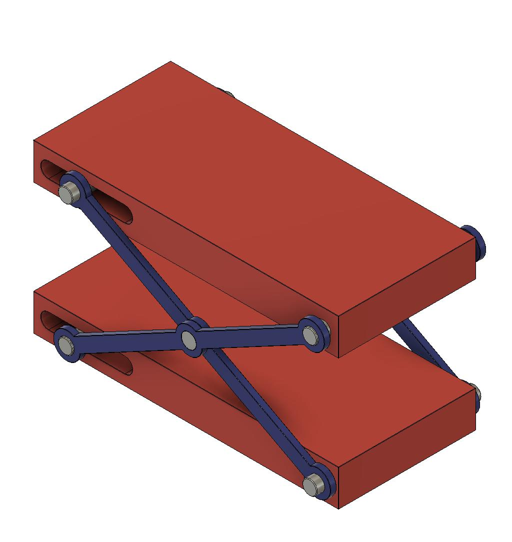

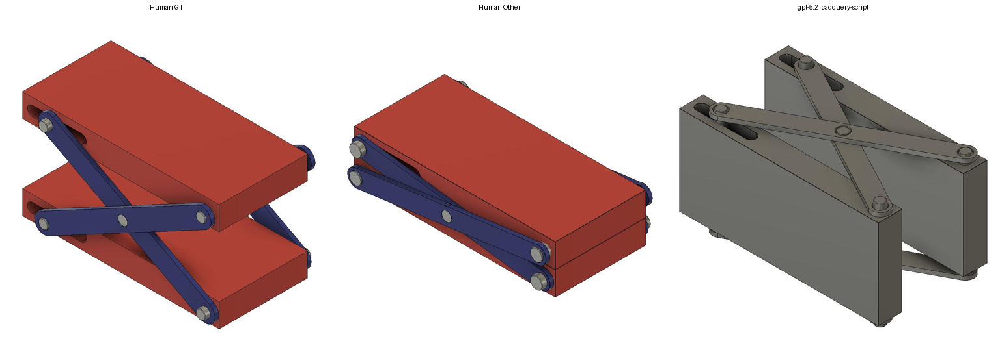

Request ID: 3YH2WFSRM22W7DKT_1769779150.98797
Edit ID: 3YH2WFSRM22W7DKT_1769783009.070806, User: 3YH2WFSRM22W7DKT, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/3YH2WFSRM22W7DKT_1769783231.5078888_toprightiso.jpg
Edit ID: SUJ2G2UMJQR7PMBX_1770350685.795295, User: SUJ2G2UMJQR7PMBX, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/SUJ2G2UMJQR7PMBX_1770350909.101281_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771095465.379369, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771097091.219999_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771463239.903039.
No images found for format ['jpg', 'png'] in brep gemini-3-pro_cadquery-script_1771469575.6552541.
Instruction text:
Imagine the black handle is a stan

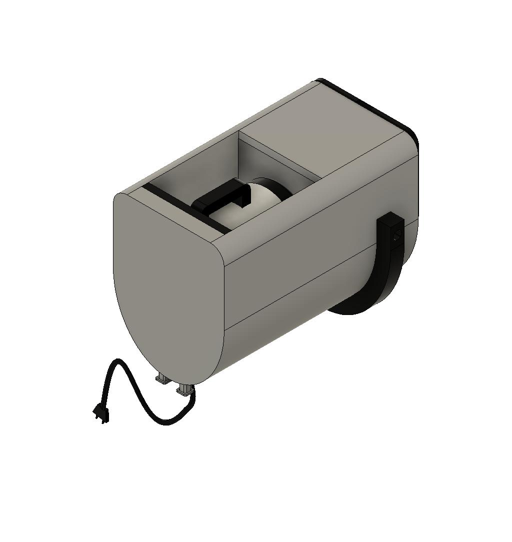

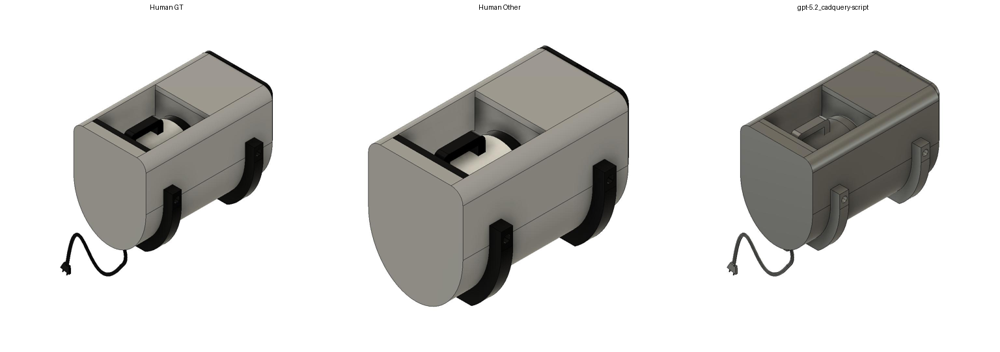

Request ID: 3YH2WFSRM22W7DKT_1769782403.586036
Edit ID: SUJ2G2UMJQR7PMBX_1770351426.174486, User: SUJ2G2UMJQR7PMBX, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/SUJ2G2UMJQR7PMBX_1770352544.57821_toprightiso.jpg
Edit ID: 3YH2WFSRM22W7DKT_1770281370.300064, User: 3YH2WFSRM22W7DKT, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/3YH2WFSRM22W7DKT_1770282363.071411_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771097091.221183, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771097959.1147761_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771463592.9286258.
No images found for format ['jpg', 'png'] in brep gemini-3-pro_cadquery-script_1771470656.620255.
Instruction text:
Change the current plug for Europl

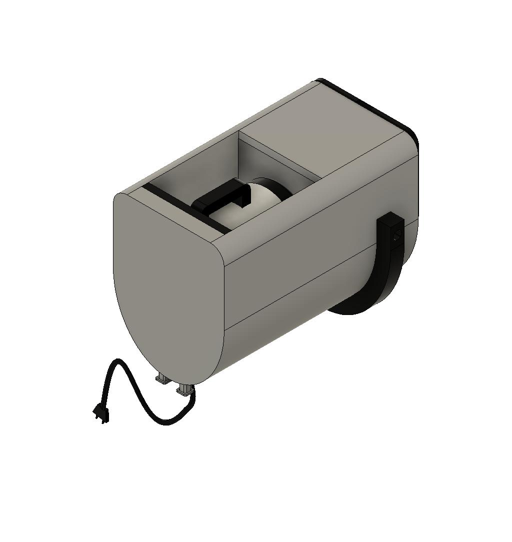

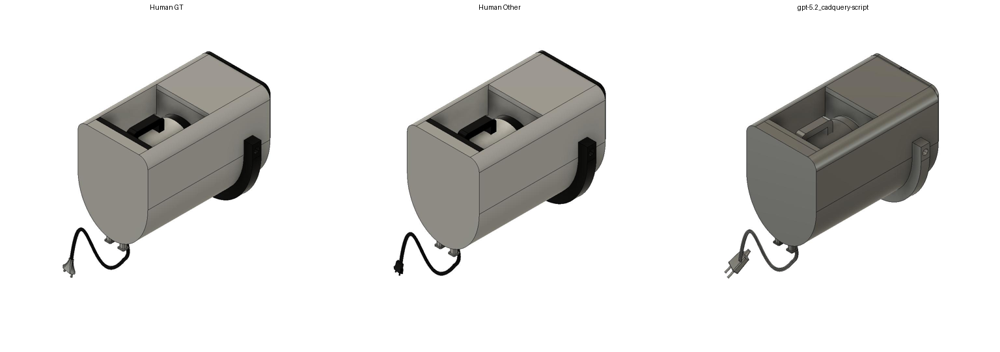

Request ID: 3YH2WFSRM22W7DKT_1769783385.069543
Edit ID: 3YH2WFSRM22W7DKT_1769784002.8913012, User: 3YH2WFSRM22W7DKT, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/3YH2WFSRM22W7DKT_1769784307.245124_toprightiso.jpg
Edit ID: SUJ2G2UMJQR7PMBX_1770350967.1341498, User: SUJ2G2UMJQR7PMBX, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/SUJ2G2UMJQR7PMBX_1770351283.911096_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771097959.1156101, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771098983.927537_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771464127.7421372.
Edit ID: gemini-3-pro_cadquery-script_1771470656.623945, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-A

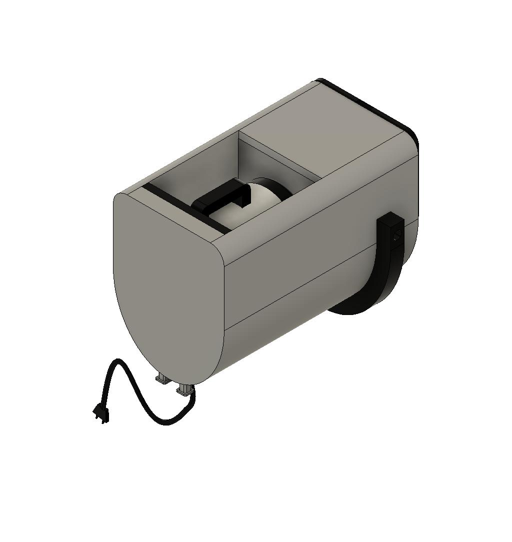

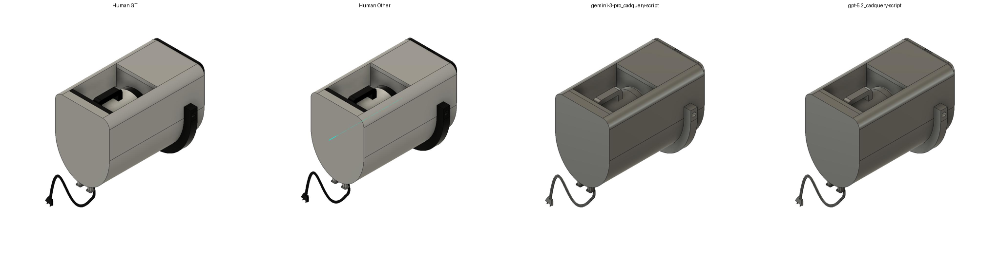

Request ID: 4E22SJE7QVTSP2E3_1758737060.465216
Edit ID: 4E22SJE7QVTSP2E3_1758737324.313555, User: 4E22SJE7QVTSP2E3, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4E22SJE7QVTSP2E3_1758737364.5100071_toprightiso.jpg
Edit ID: SUJ2G2UMJQR7PMBX_1759745519.301497, User: SUJ2G2UMJQR7PMBX, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/SUJ2G2UMJQR7PMBX_1759745543.117889_toprightiso.jpg
Edit ID: claude-sonnet-4.5_cadquery-script_1770984960.667063, User: claude-sonnet-4.5_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/claude-sonnet-4.5_cadquery-script_1770985276.916856_toprightiso.jpg
Edit ID: gemini-3-pro_cadquery-script_1771005086.439685, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gemini-3-pro_cadquery-sc

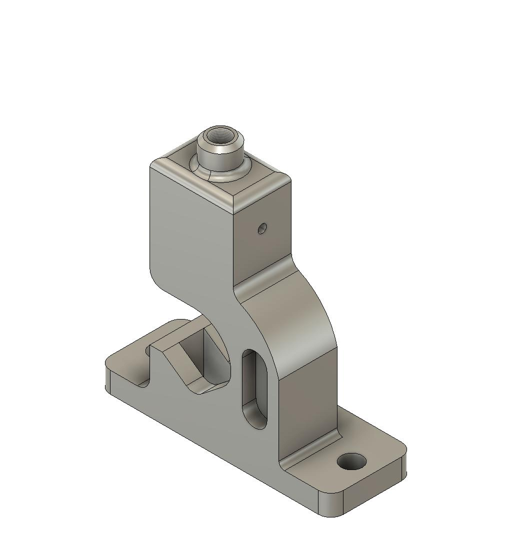

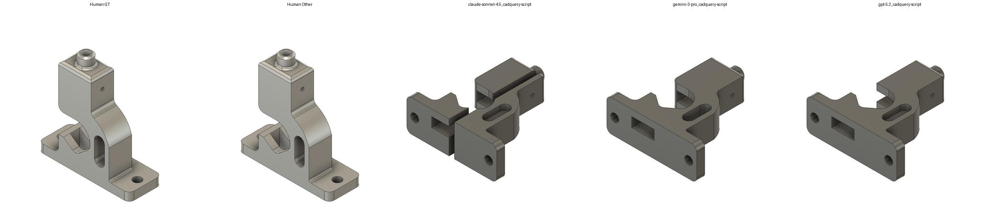

Request ID: 4E22SJE7QVTSP2E3_1758737118.288898
Edit ID: SUJ2G2UMJQR7PMBX_1760005391.2524369, User: SUJ2G2UMJQR7PMBX, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/SUJ2G2UMJQR7PMBX_1760005565.354083_toprightiso.jpg
Edit ID: 4E22SJE7QVTSP2E3_1759907329.460883, User: 4E22SJE7QVTSP2E3, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4E22SJE7QVTSP2E3_1759907508.509569_toprightiso.jpg
Edit ID: claude-sonnet-4.5_cadquery-script_1770985784.758003, User: claude-sonnet-4.5_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/claude-sonnet-4.5_cadquery-script_1770986055.487199_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep gemini-3-pro_cadquery-script_1771007562.564814.
Edit ID: gpt-5.2_cadquery-script_1771007849.4978309, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC2

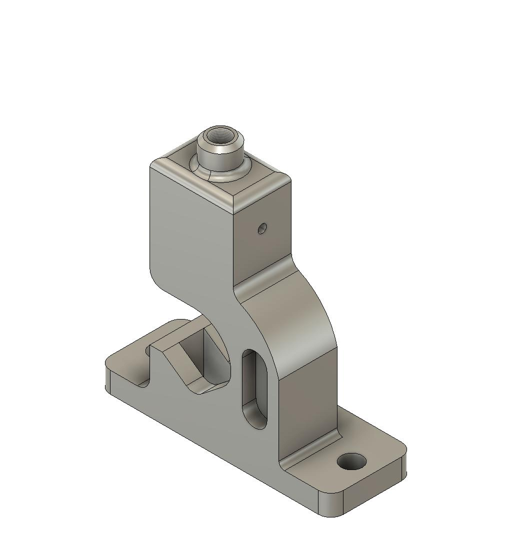

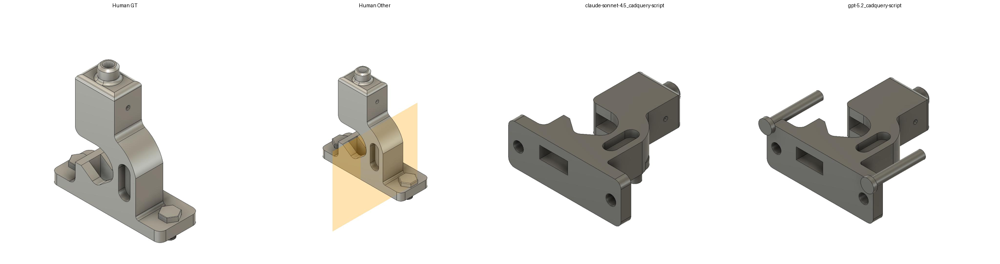

Request ID: 4E22SJE7QVTSP2E3_1758737238.499021
Edit ID: 4E22SJE7QVTSP2E3_1758737540.478013, User: 4E22SJE7QVTSP2E3, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4E22SJE7QVTSP2E3_1758737863.425611_toprightiso.jpg
Edit ID: SUJ2G2UMJQR7PMBX_1759819249.892704, User: SUJ2G2UMJQR7PMBX, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/SUJ2G2UMJQR7PMBX_1759819510.1979048_toprightiso.jpg
Edit ID: gemini-3-pro_cadquery-script_1771006061.635974, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gemini-3-pro_cadquery-script_1771006663.395092_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771007318.386133, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771007849.4950569_toprig

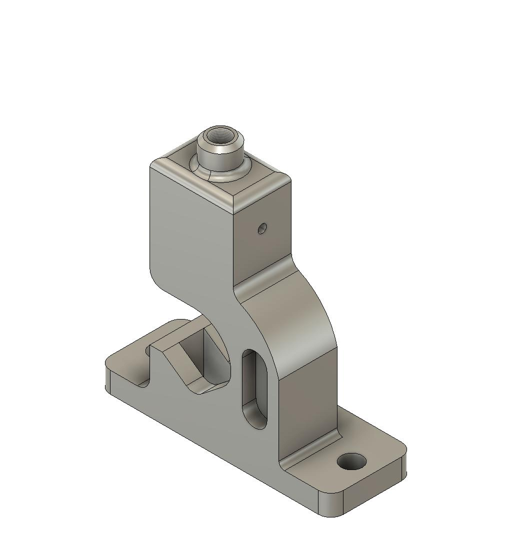

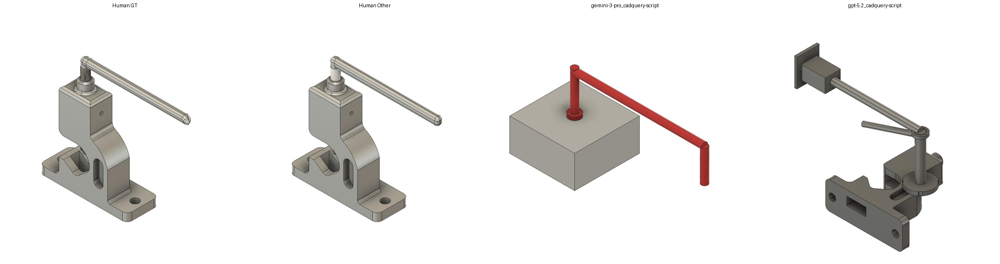

Request ID: 4S7JQK6ZQMAD25GL_1758863141.735564
Edit ID: 4E22SJE7QVTSP2E3_1759932687.103946, User: 4E22SJE7QVTSP2E3, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4E22SJE7QVTSP2E3_1759932719.14223_toprightiso.jpg
Edit ID: 4S7JQK6ZQMAD25GL_1758860199.029181, User: 4S7JQK6ZQMAD25GL, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4S7JQK6ZQMAD25GL_1758860219.557066_toprightiso.jpg
Edit ID: gemini-3-pro_cadquery-script_1771011065.747093, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gemini-3-pro_cadquery-script_1771011927.188559_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771012467.970748, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771013445.783168_toprighti

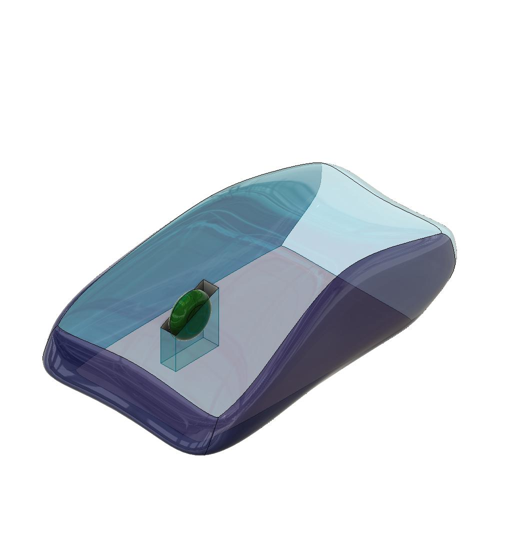

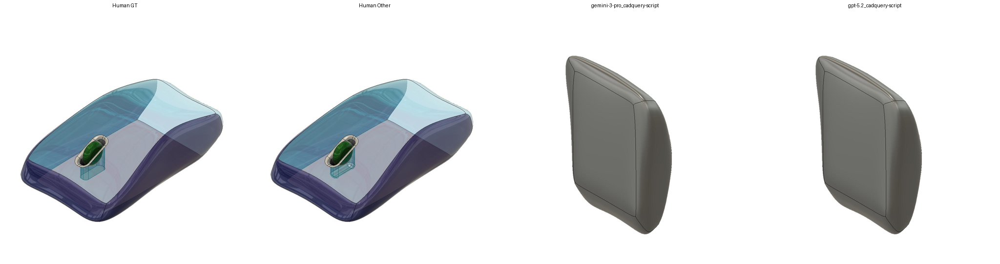

Request ID: 4S7JQK6ZQMAD25GL_1758863286.214549
Edit ID: 4E22SJE7QVTSP2E3_1759933087.734509, User: 4E22SJE7QVTSP2E3, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4E22SJE7QVTSP2E3_1759933372.0768251_toprightiso.jpg
Edit ID: 4S7JQK6ZQMAD25GL_1758860513.0750852, User: 4S7JQK6ZQMAD25GL, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4S7JQK6ZQMAD25GL_1758860663.6610408_toprightiso.jpg
Edit ID: gemini-3-pro_cadquery-script_1771012021.976305, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gemini-3-pro_cadquery-script_1771013071.300748_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771014068.081225, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771015220.639067_topri

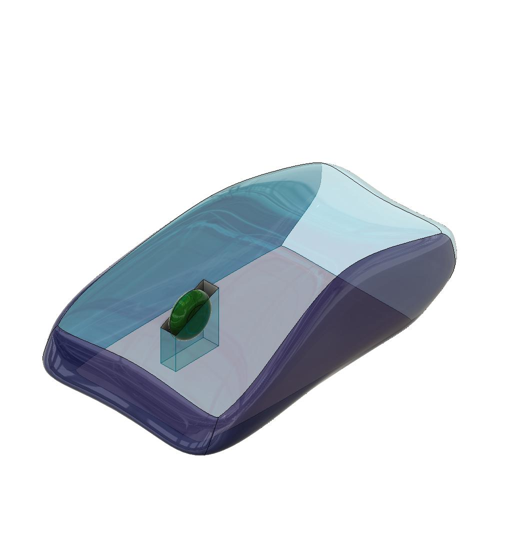

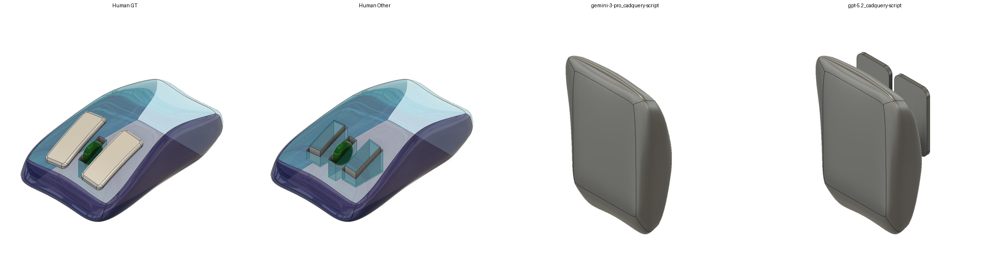

Request ID: 4S7JQK6ZQMAD25GL_1758863403.376244
Edit ID: 4S7JQK6ZQMAD25GL_1758860901.1554198, User: 4S7JQK6ZQMAD25GL, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4S7JQK6ZQMAD25GL_1758861187.827584_toprightiso.jpg
Edit ID: 4E22SJE7QVTSP2E3_1759933513.452847, User: 4E22SJE7QVTSP2E3, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4E22SJE7QVTSP2E3_1759933848.352789_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771013445.784674, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771014068.0798788_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771443993.6465511.
No images found for format ['jpg', 'png'] in brep gemini-3-pro_cadquery-script_1771497677.55266.
Instruction text:
Add a sliding switch on the botto

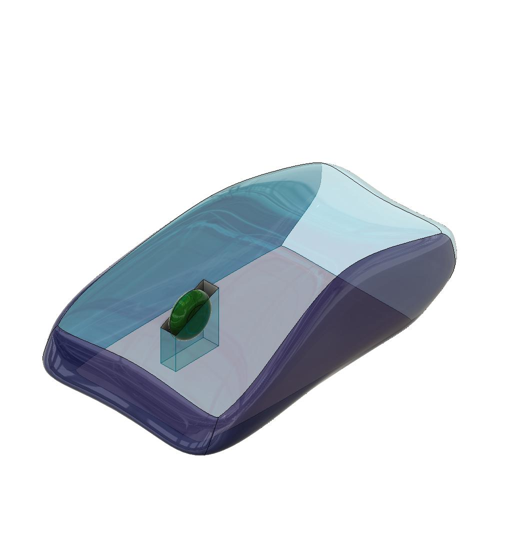

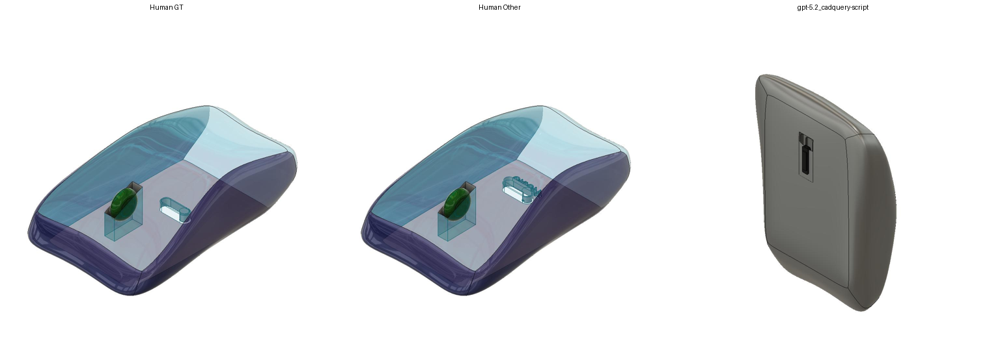

Request ID: B7A2N74ZJBF9MZHU_1770166308.11235
Edit ID: 4E22SJE7QVTSP2E3_1770281719.767215, User: 4E22SJE7QVTSP2E3, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4E22SJE7QVTSP2E3_1770281761.222699_toprightiso.jpg
Edit ID: B7A2N74ZJBF9MZHU_1770166542.261875, User: B7A2N74ZJBF9MZHU, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/B7A2N74ZJBF9MZHU_1770166566.935083_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771134520.649917, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771135676.064883_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771586293.639093.
Edit ID: gemini-3-pro_cadquery-script_1771536213.5702138, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autod

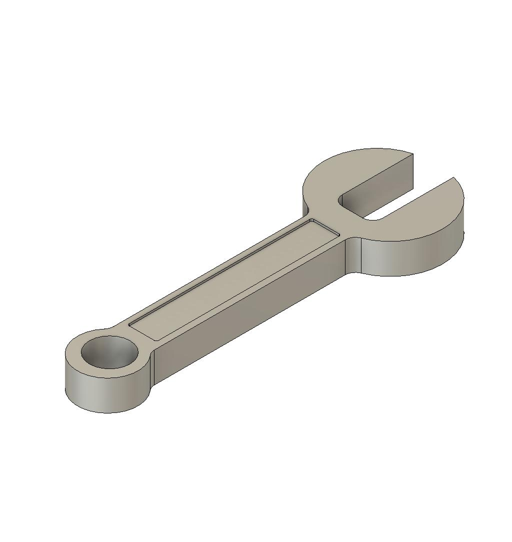

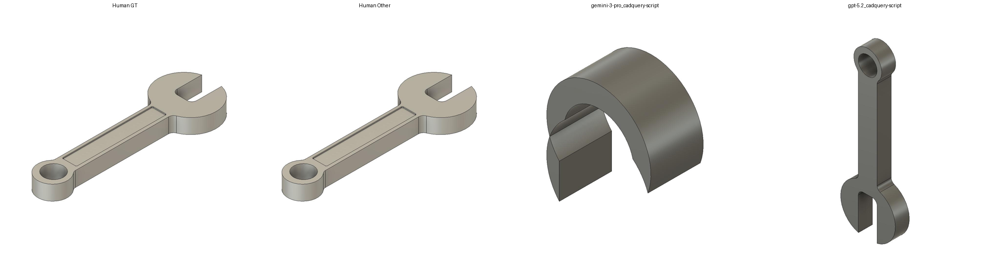

Request ID: B7A2N74ZJBF9MZHU_1770166901.871316
Edit ID: 4E22SJE7QVTSP2E3_1770283775.177854, User: 4E22SJE7QVTSP2E3, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4E22SJE7QVTSP2E3_1770283886.304938_toprightiso.jpg
Edit ID: B7A2N74ZJBF9MZHU_1770167087.392596, User: B7A2N74ZJBF9MZHU, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/B7A2N74ZJBF9MZHU_1770167138.529792_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771137533.994237, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771138136.368067_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771472566.8134458.
No images found for format ['jpg', 'png'] in brep gemini-3-pro_cadquery-script_1771539538.090421.
Instruction text:
Use geometry of cylindrical hole d

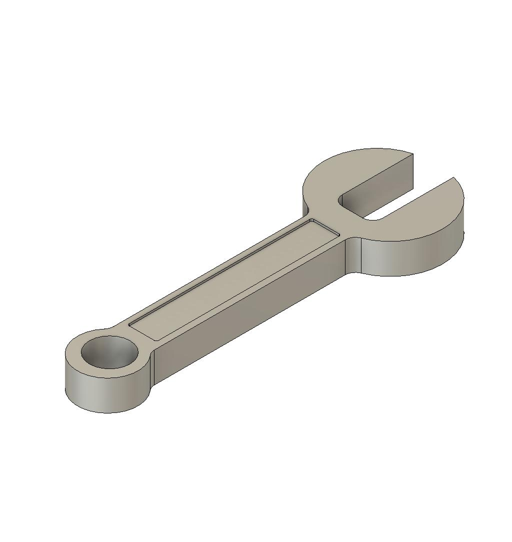

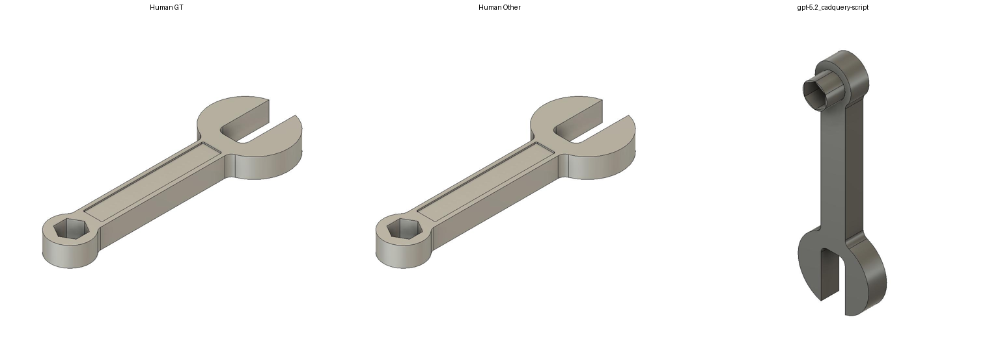

Request ID: B7A2N74ZJBF9MZHU_1770167800.9857888
Edit ID: 4E22SJE7QVTSP2E3_1770283998.409992, User: 4E22SJE7QVTSP2E3, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4E22SJE7QVTSP2E3_1770284176.012213_toprightiso.jpg
Edit ID: B7A2N74ZJBF9MZHU_1770168016.035979, User: B7A2N74ZJBF9MZHU, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/B7A2N74ZJBF9MZHU_1770168158.647497_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771135676.065696, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771137533.972336_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771586390.1509929.
Edit ID: gemini-3-pro_cadquery-script_1771537431.902715, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Aut

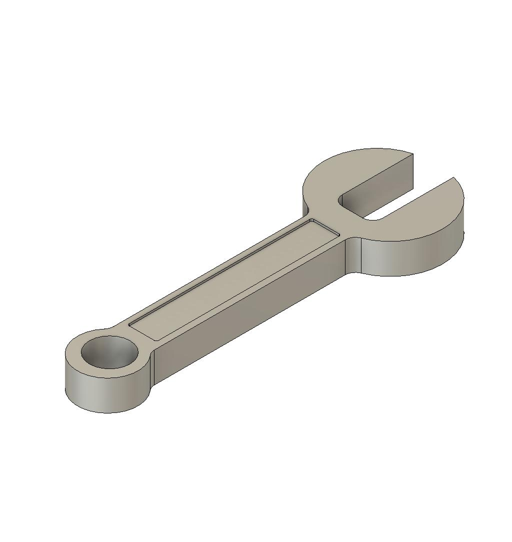

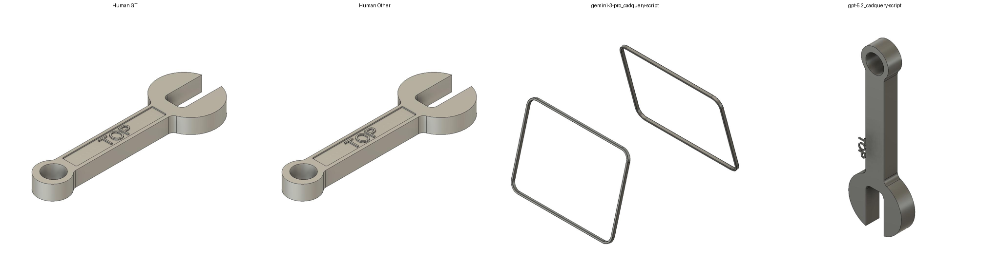

Request ID: B7A2N74ZJBF9MZHU_1770169445.8914912
Edit ID: EHM2HMQDME2U85QB_1770276166.6178298, User: EHM2HMQDME2U85QB, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/EHM2HMQDME2U85QB_1770276190.115674_toprightiso.jpg
Edit ID: B7A2N74ZJBF9MZHU_1770169630.08943, User: B7A2N74ZJBF9MZHU, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/B7A2N74ZJBF9MZHU_1770169670.772366_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771168523.4612548, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771169537.281322_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771586724.7647722.
No images found for format ['jpg', 'png'] in brep gemini-3-pro_cadquery-script_1771564237.236932.
Instruction text:
Add chamfer to main/biggest cyli

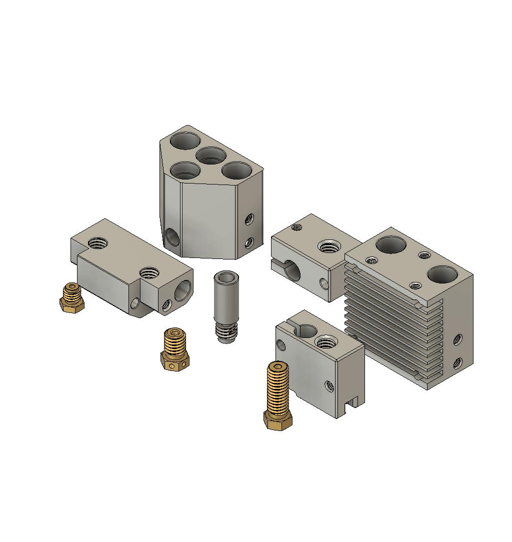

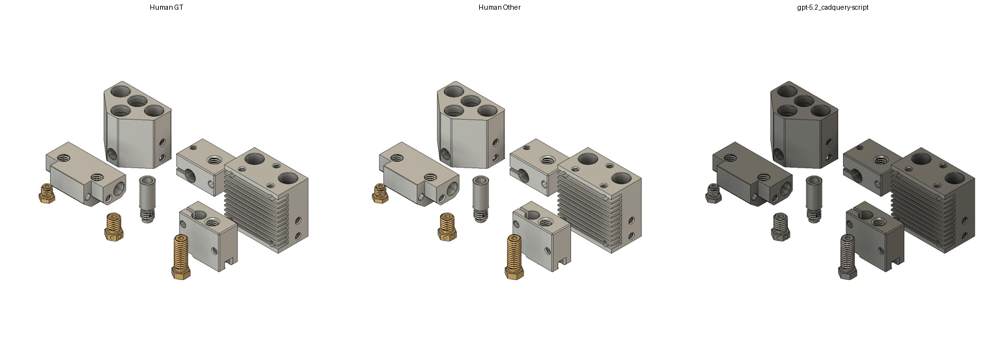

Request ID: B7A2N74ZJBF9MZHU_1770169718.2982779
Edit ID: B7A2N74ZJBF9MZHU_1770169815.32406, User: B7A2N74ZJBF9MZHU, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/B7A2N74ZJBF9MZHU_1770169872.203006_toprightiso.jpg
Edit ID: EHM2HMQDME2U85QB_1770273787.897383, User: EHM2HMQDME2U85QB, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/EHM2HMQDME2U85QB_1770273882.8047261_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771170958.1185641, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771171306.787411_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771480483.7610571.
No images found for format ['jpg', 'png'] in brep gemini-3-pro_cadquery-script_1771639622.019134.
Instruction text:
Reduce overall height of Nozzle 

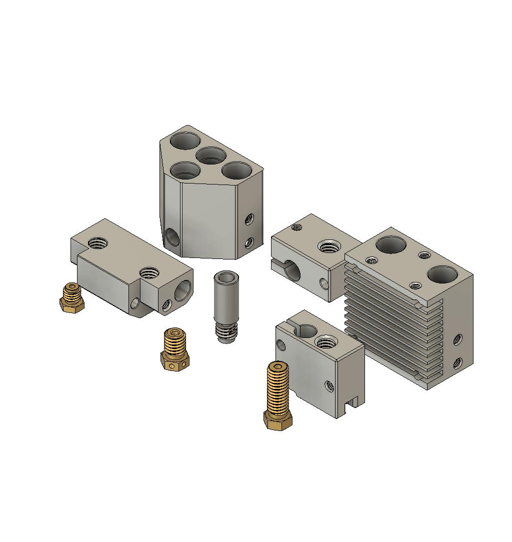

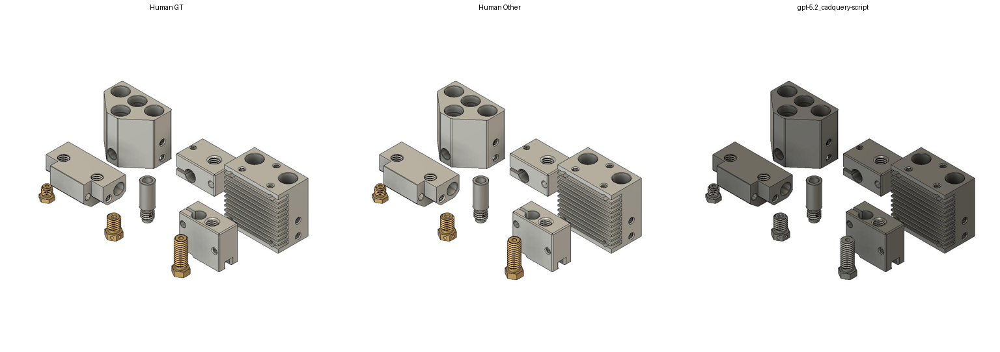

Request ID: B7A2N74ZJBF9MZHU_1770169975.851399
Edit ID: B7A2N74ZJBF9MZHU_1770170200.427947, User: B7A2N74ZJBF9MZHU, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/B7A2N74ZJBF9MZHU_1770170732.361324_toprightiso.jpg
Edit ID: EHM2HMQDME2U85QB_1770274111.1332731, User: EHM2HMQDME2U85QB, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/EHM2HMQDME2U85QB_1770274274.016923_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771169537.282132, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771170958.1093462_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771586778.256877.
Edit ID: gemini-3-pro_cadquery-script_1771564237.23856, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Auto

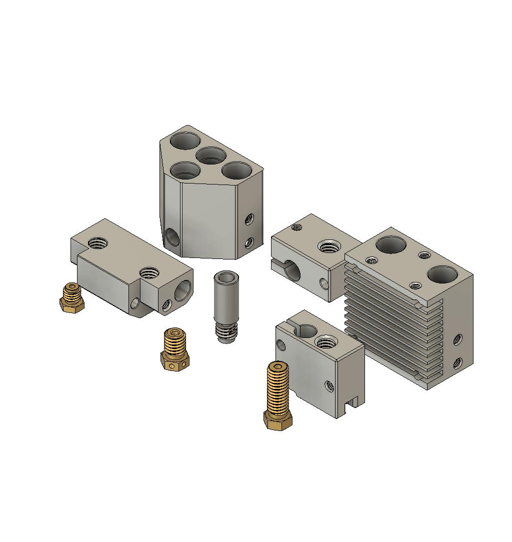

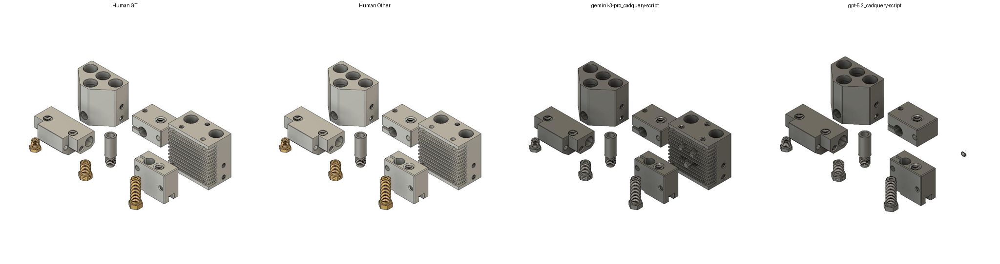

Request ID: B7A2N74ZJBF9MZHU_1770171470.1448698
Edit ID: B7A2N74ZJBF9MZHU_1770171574.0493498, User: B7A2N74ZJBF9MZHU, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/B7A2N74ZJBF9MZHU_1770171604.36757_toprightiso.jpg
Edit ID: 4E22SJE7QVTSP2E3_1770298527.59247, User: 4E22SJE7QVTSP2E3, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4E22SJE7QVTSP2E3_1770298553.736796_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771051108.7779992, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771051696.241556_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771453114.595084.
Edit ID: gemini-3-pro_cadquery-script_1771512417.235435, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Auto

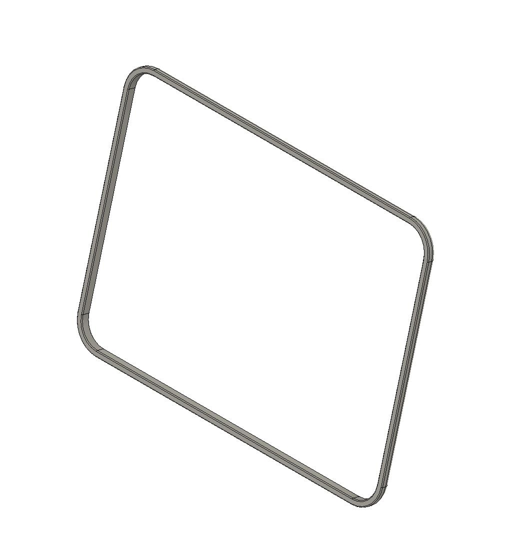

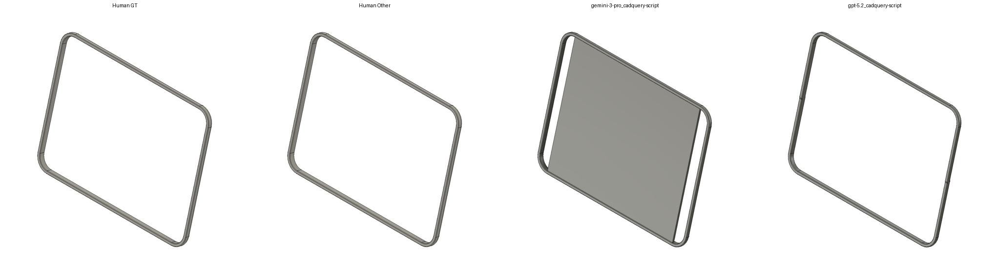

Request ID: B7A2N74ZJBF9MZHU_1770171700.697783
Edit ID: 4E22SJE7QVTSP2E3_1770298897.9248798, User: 4E22SJE7QVTSP2E3, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4E22SJE7QVTSP2E3_1770298949.912307_toprightiso.jpg
Edit ID: B7A2N74ZJBF9MZHU_1770171812.336973, User: B7A2N74ZJBF9MZHU, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/B7A2N74ZJBF9MZHU_1770171866.426871_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771054198.839276, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771055489.714899_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771453792.894491.
No images found for format ['jpg', 'png'] in brep gemini-3-pro_cadquery-script_1771625139.32935.
Instruction text:
Remove the largest radius that is a

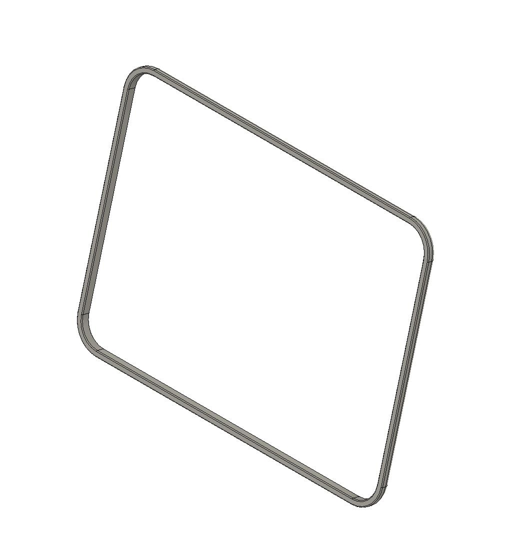

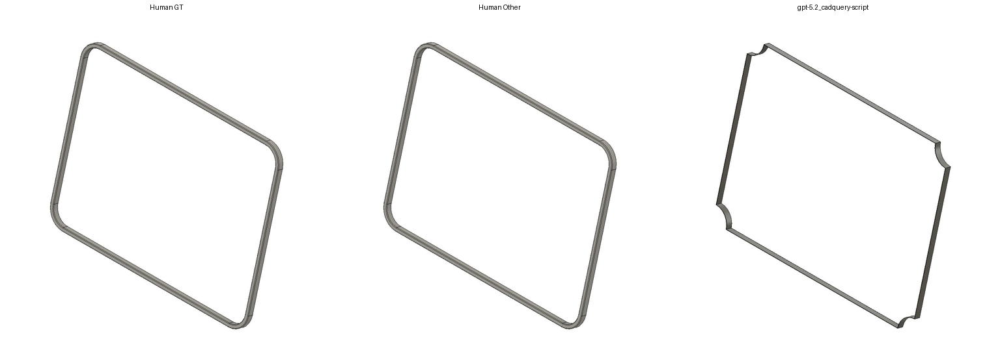

Request ID: B7A2N74ZJBF9MZHU_1770172545.5244548
Edit ID: B7A2N74ZJBF9MZHU_1770172752.354274, User: B7A2N74ZJBF9MZHU, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/B7A2N74ZJBF9MZHU_1770172865.2628522_toprightiso.jpg
Edit ID: 4E22SJE7QVTSP2E3_1770299591.6655092, User: 4E22SJE7QVTSP2E3, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4E22SJE7QVTSP2E3_1770299808.387549_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771051696.242371, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771054198.838351_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771585655.919806.
No images found for format ['jpg', 'png'] in brep gemini-3-pro_cadquery-script_1771444201.307541.
Instruction text:
If edge with bigger radius is co

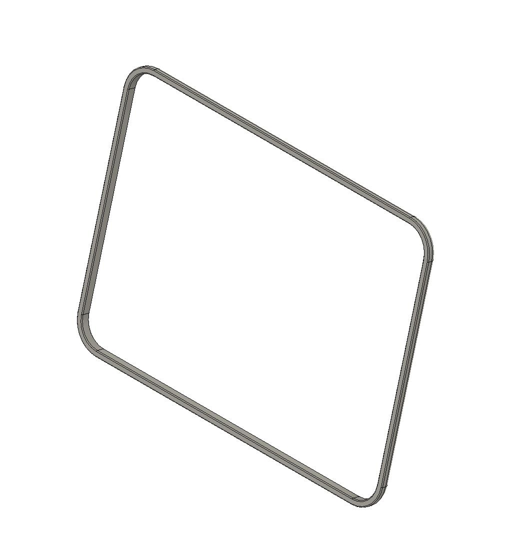

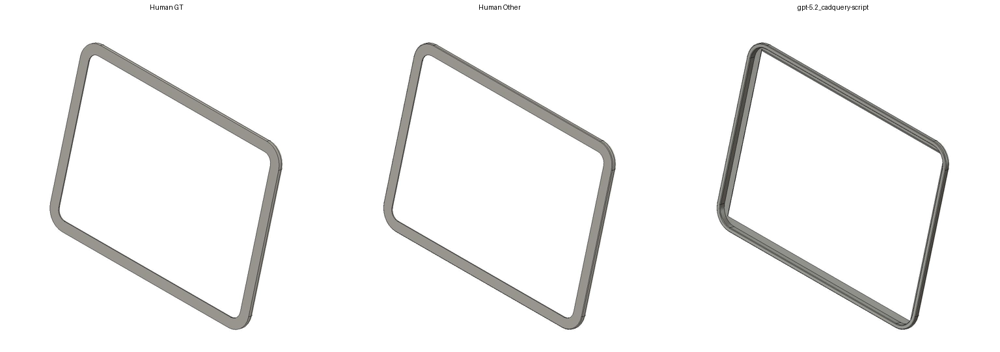

Request ID: B7A2N74ZJBF9MZHU_1770174133.012106
Edit ID: B7A2N74ZJBF9MZHU_1770174206.720026, User: B7A2N74ZJBF9MZHU, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/B7A2N74ZJBF9MZHU_1770174221.1854131_toprightiso.jpg
Edit ID: SUJ2G2UMJQR7PMBX_1770271720.736626, User: SUJ2G2UMJQR7PMBX, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/SUJ2G2UMJQR7PMBX_1770271748.8171039_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771090260.778689, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771091674.9915452_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771461968.0479648.
Edit ID: gemini-3-pro_cadquery-script_1771465920.4619389, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-

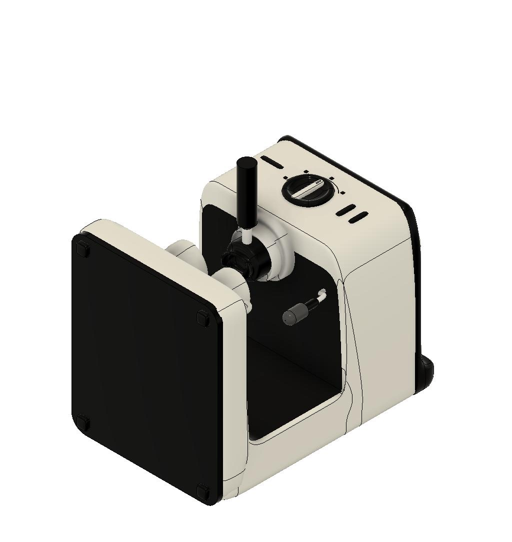

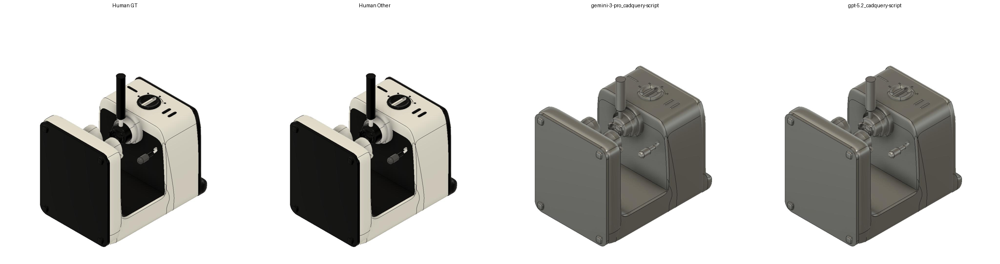

Request ID: B7A2N74ZJBF9MZHU_1770174308.67968
Edit ID: B7A2N74ZJBF9MZHU_1770174391.3786712, User: B7A2N74ZJBF9MZHU, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/B7A2N74ZJBF9MZHU_1770174468.756362_toprightiso.jpg
Edit ID: SUJ2G2UMJQR7PMBX_1770277374.572247, User: SUJ2G2UMJQR7PMBX, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/SUJ2G2UMJQR7PMBX_1770277421.680935_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771093391.274008, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771095465.3783832_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771462571.684744.
Edit ID: gemini-3-pro_cadquery-script_1771468041.5513542, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Aut

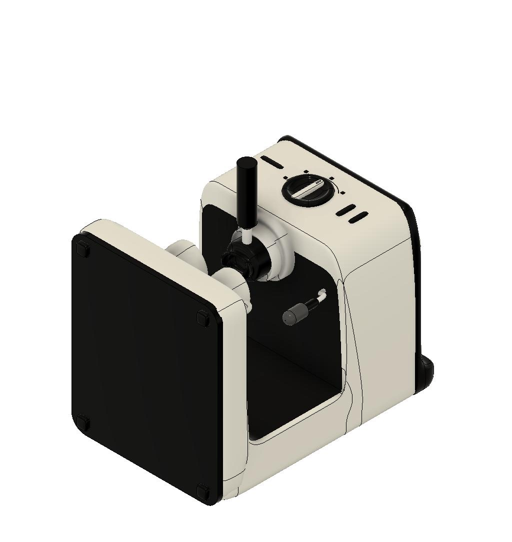

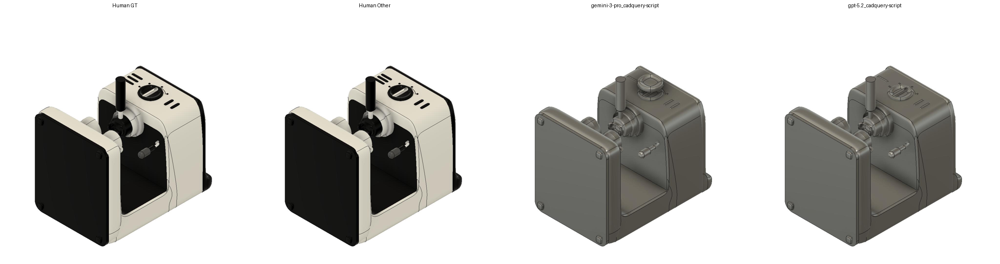

Request ID: B7A2N74ZJBF9MZHU_1770174519.556716
Edit ID: B7A2N74ZJBF9MZHU_1770174694.3690329, User: B7A2N74ZJBF9MZHU, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/B7A2N74ZJBF9MZHU_1770174801.8832462_toprightiso.jpg
Edit ID: SUJ2G2UMJQR7PMBX_1770278220.31356, User: SUJ2G2UMJQR7PMBX, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/SUJ2G2UMJQR7PMBX_1770278434.417848_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771091674.992308, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771093391.272267_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771586042.7425332.
No images found for format ['jpg', 'png'] in brep gemini-3-pro_cadquery-script_1771468041.5480409.
Instruction text:
Add rectangular openining to the

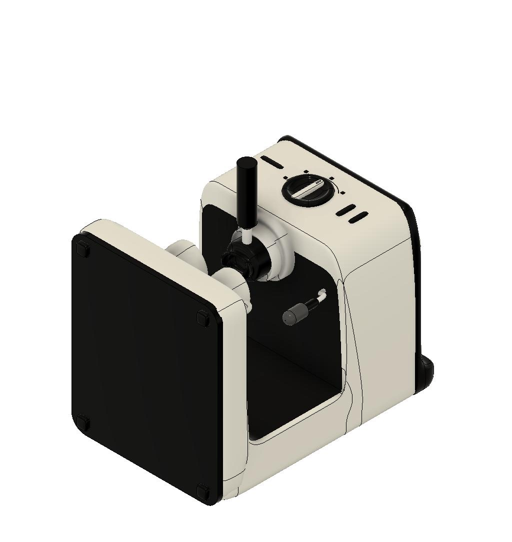

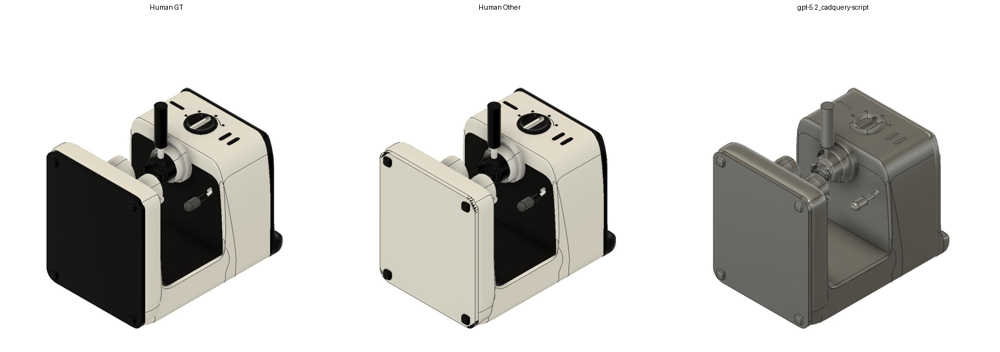

Request ID: F332D3FXML85WLR2_1769424096.996583
Edit ID: DYP2J9CYL7X46RLQ_1770274761.434098, User: DYP2J9CYL7X46RLQ, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/DYP2J9CYL7X46RLQ_1770274796.578121_toprightiso.jpg
Edit ID: F332D3FXML85WLR2_1769424776.2441568, User: F332D3FXML85WLR2, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/F332D3FXML85WLR2_1769424844.610955_toprightiso.jpg
Edit ID: claude-sonnet-4.5_cadquery-script_1771000838.919619, User: claude-sonnet-4.5_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/claude-sonnet-4.5_cadquery-script_1771001155.412163_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771048998.549462, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771049140

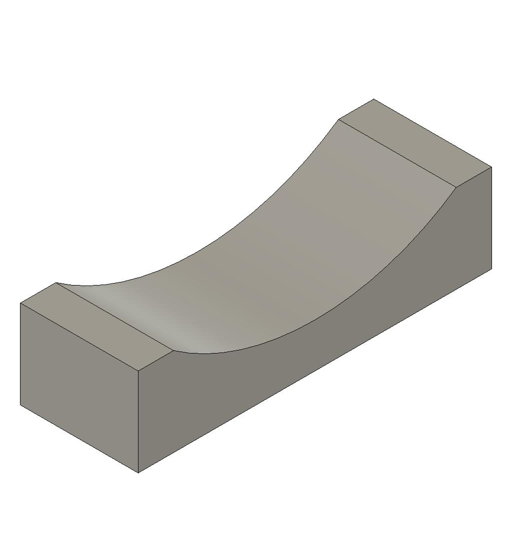

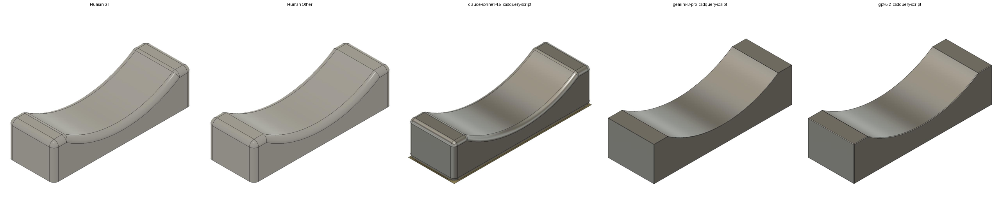

Request ID: F332D3FXML85WLR2_1769607142.566352
Edit ID: F332D3FXML85WLR2_1769607294.73713, User: F332D3FXML85WLR2, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/F332D3FXML85WLR2_1769608193.091736_toprightiso.jpg
Edit ID: DYP2J9CYL7X46RLQ_1770263941.737219, User: DYP2J9CYL7X46RLQ, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/DYP2J9CYL7X46RLQ_1770264376.3208_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771086666.681466, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771089547.5143418_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771585971.711572.
Edit ID: gemini-3-pro_cadquery-script_1771464028.950561, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodes

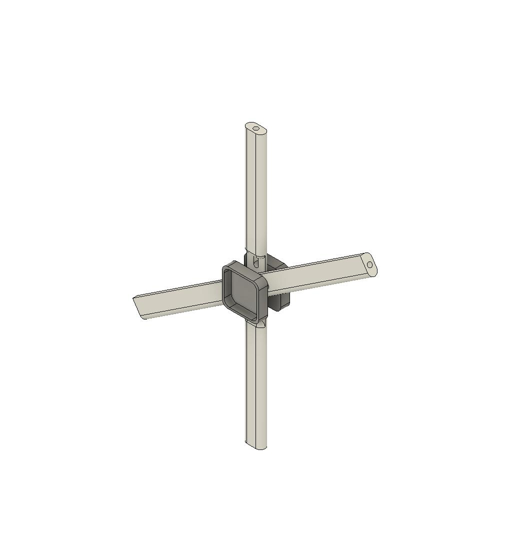

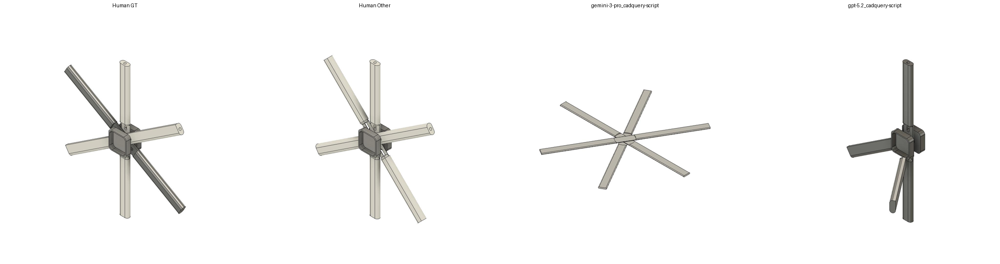

Request ID: F332D3FXML85WLR2_1770204558.429523
Edit ID: F332D3FXML85WLR2_1770204591.9413471, User: F332D3FXML85WLR2, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/F332D3FXML85WLR2_1770204605.599328_toprightiso.jpg
Edit ID: DYP2J9CYL7X46RLQ_1770262982.264448, User: DYP2J9CYL7X46RLQ, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/DYP2J9CYL7X46RLQ_1770263010.379529_toprightiso.jpg
Edit ID: claude-sonnet-4.5_cadquery-script_1771013614.274773, User: claude-sonnet-4.5_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/claude-sonnet-4.5_cadquery-script_1771013868.2541041_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771085829.549876, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_177108666

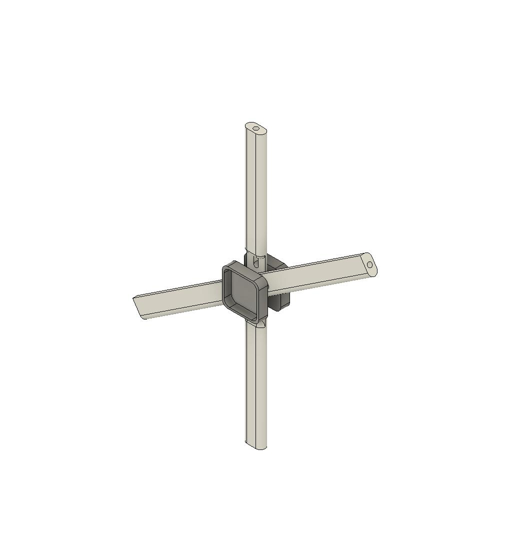

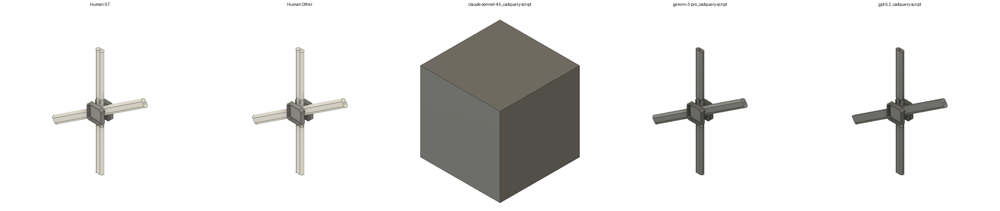

Request ID: F332D3FXML85WLR2_1770204696.542443
Edit ID: DYP2J9CYL7X46RLQ_1770279480.495442, User: DYP2J9CYL7X46RLQ, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/DYP2J9CYL7X46RLQ_1770280051.274079_toprightiso.jpg
Edit ID: F332D3FXML85WLR2_1770204739.477653, User: F332D3FXML85WLR2, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/F332D3FXML85WLR2_1770204803.887373_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771089547.515269, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771090260.777749_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771461588.218473.
Edit ID: gemini-3-pro_cadquery-script_1771465311.3338711, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Auto

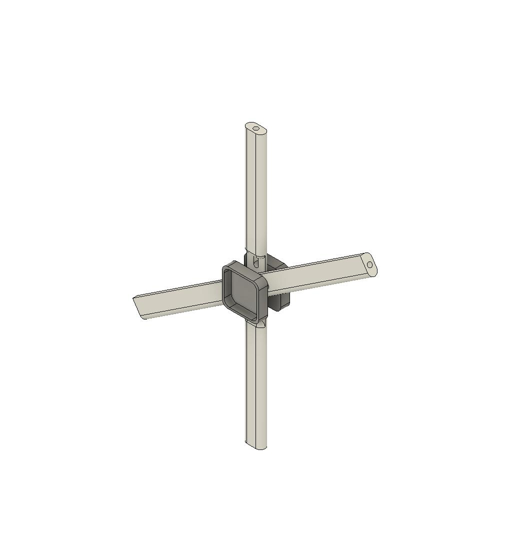

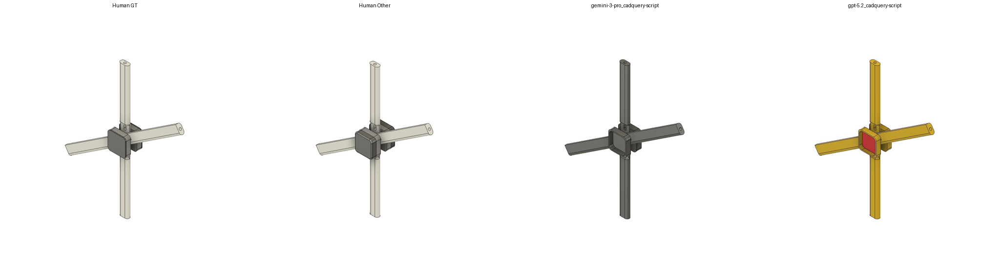

Request ID: F332D3FXML85WLR2_1770205912.1187751
Edit ID: DYP2J9CYL7X46RLQ_1770276397.463688, User: DYP2J9CYL7X46RLQ, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/DYP2J9CYL7X46RLQ_1770276631.2854028_toprightiso.jpg
Edit ID: F332D3FXML85WLR2_1770205986.614271, User: F332D3FXML85WLR2, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/F332D3FXML85WLR2_1770206259.538721_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771050708.952331, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771051108.774542_toprightiso.jpg
Edit ID: claude-sonnet-4.5_cadquery-script_1771452497.9535968, User: claude-sonnet-4.5_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/claude-sonnet-4.5_cadquery-script_17714527

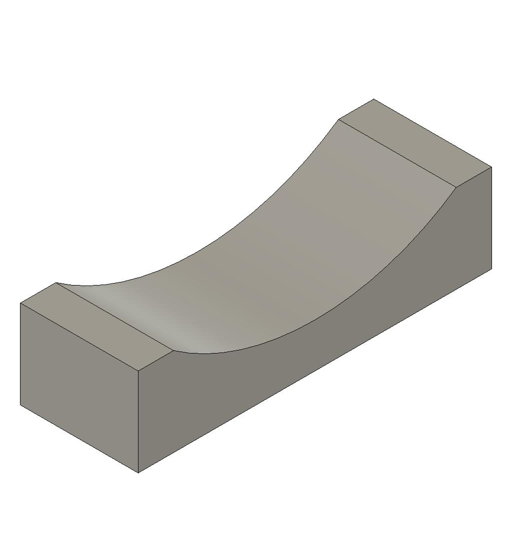

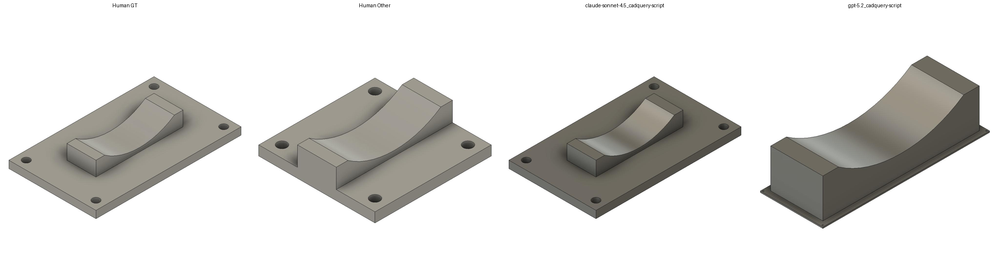

Request ID: F332D3FXML85WLR2_1770206307.074256
Edit ID: DYP2J9CYL7X46RLQ_1770277233.566407, User: DYP2J9CYL7X46RLQ, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/DYP2J9CYL7X46RLQ_1770277706.235426_toprightiso.jpg
Edit ID: F332D3FXML85WLR2_1770206601.118546, User: F332D3FXML85WLR2, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/F332D3FXML85WLR2_1770206810.449016_toprightiso.jpg
Edit ID: claude-sonnet-4.5_cadquery-script_1771001155.413743, User: claude-sonnet-4.5_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/claude-sonnet-4.5_cadquery-script_1771001464.5705879_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771049140.75717, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771050708.

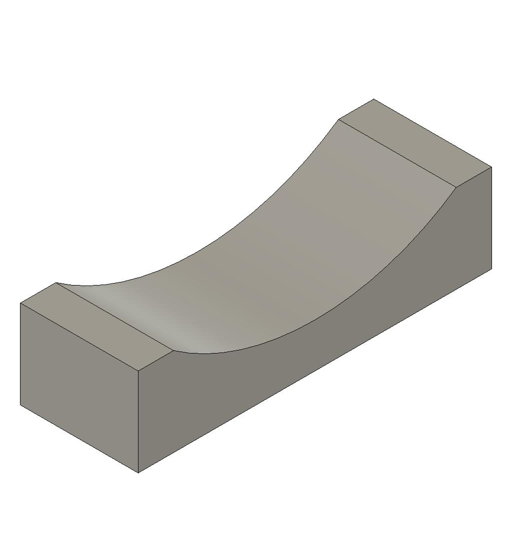

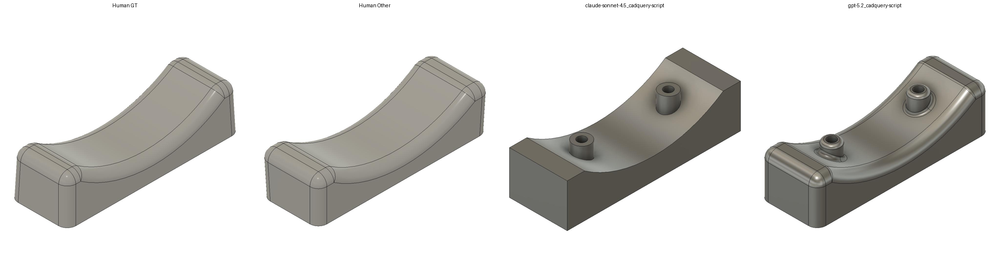

Request ID: F332D3FXML85WLR2_1770208282.204381
Edit ID: F332D3FXML85WLR2_1770208431.9496078, User: F332D3FXML85WLR2, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/F332D3FXML85WLR2_1770208507.059219_toprightiso.jpg
Edit ID: 4S7JQK6ZQMAD25GL_1770264609.088493, User: 4S7JQK6ZQMAD25GL, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4S7JQK6ZQMAD25GL_1770264713.287425_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771132214.664621, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771133176.6054132_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771471921.746874.
No images found for format ['jpg', 'png'] in brep gemini-3-pro_cadquery-script_1771638860.692922.
Instruction text:
Left side of the whistle is missi

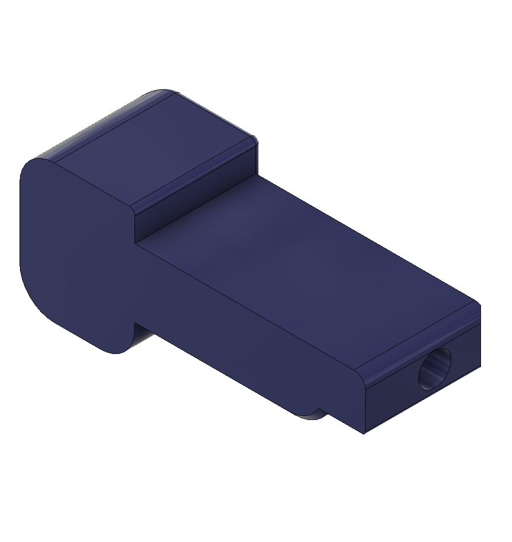

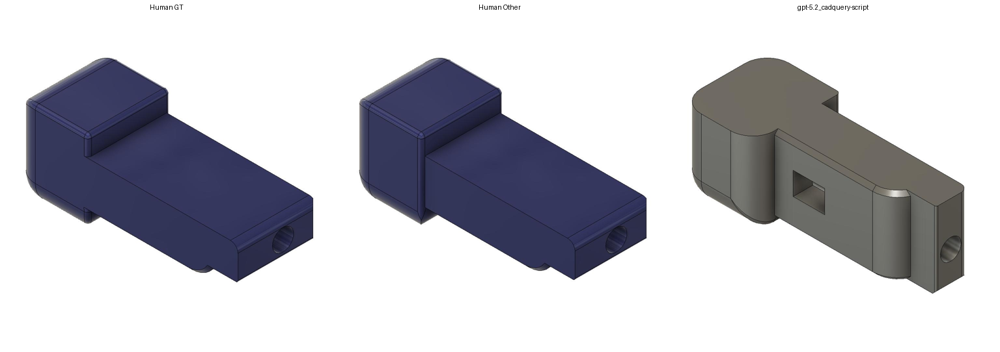

Request ID: F332D3FXML85WLR2_1770208371.265217
Edit ID: 4S7JQK6ZQMAD25GL_1770265862.9459121, User: 4S7JQK6ZQMAD25GL, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4S7JQK6ZQMAD25GL_1770265973.779048_toprightiso.jpg
Edit ID: F332D3FXML85WLR2_1770210440.898651, User: F332D3FXML85WLR2, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/F332D3FXML85WLR2_1770210539.054967_toprightiso.jpg
Edit ID: claude-sonnet-4.5_cadquery-script_1771028217.710909, User: claude-sonnet-4.5_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/claude-sonnet-4.5_cadquery-script_1771028405.8937469_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771133579.460256, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_177113452

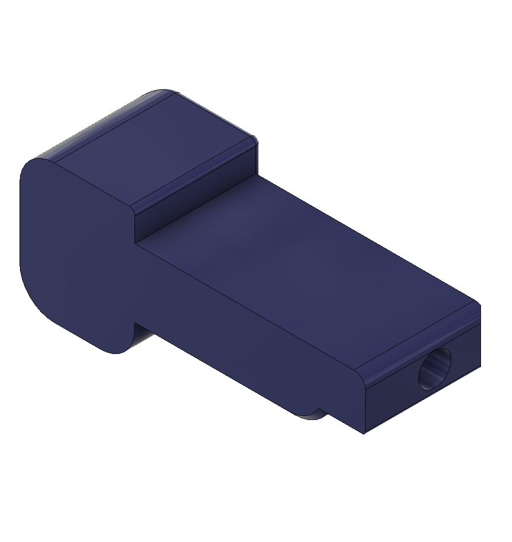

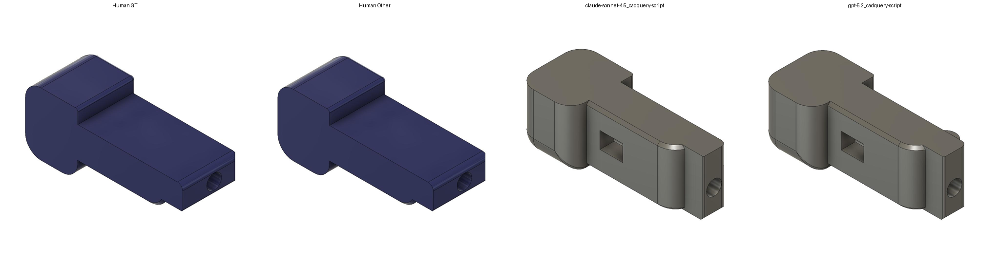

Request ID: F332D3FXML85WLR2_1770208398.300075
Edit ID: F332D3FXML85WLR2_1770210572.46644, User: F332D3FXML85WLR2, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/F332D3FXML85WLR2_1770211006.30196_toprightiso.jpg
Edit ID: 4S7JQK6ZQMAD25GL_1770268665.275477, User: 4S7JQK6ZQMAD25GL, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4S7JQK6ZQMAD25GL_1770268948.954324_toprightiso.jpg
Edit ID: claude-sonnet-4.5_cadquery-script_1771028019.05267, User: claude-sonnet-4.5_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/claude-sonnet-4.5_cadquery-script_1771028217.70864_toprightiso.jpg
Edit ID: gemini-3-pro_cadquery-script_1771533240.919405, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gemini-3-pro_cadquery-script_

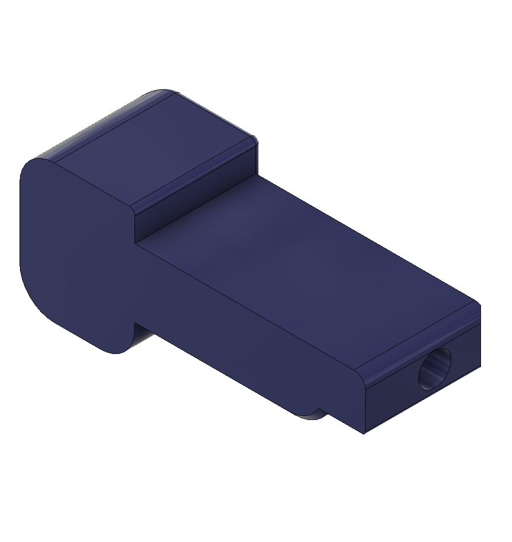

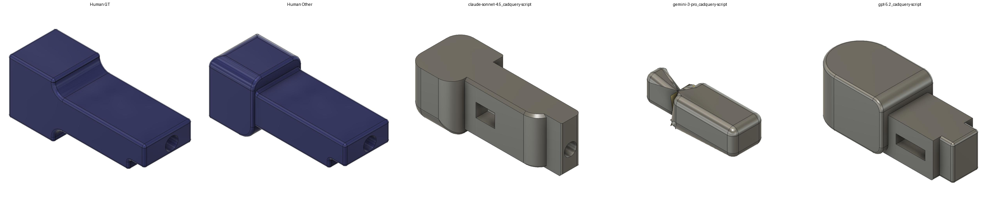

Request ID: SUJ2G2UMJQR7PMBX_1759203600.26663
Edit ID: SUJ2G2UMJQR7PMBX_1759203938.630423, User: SUJ2G2UMJQR7PMBX, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/SUJ2G2UMJQR7PMBX_1759203960.253255_toprightiso.jpg
Edit ID: DYP2J9CYL7X46RLQ_1759857824.2728472, User: DYP2J9CYL7X46RLQ, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/DYP2J9CYL7X46RLQ_1759857859.4113238_toprightiso.jpg
Edit ID: gemini-3-pro_cadquery-script_1771007562.566729, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gemini-3-pro_cadquery-script_1771008739.7318552_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771008954.312076, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771010440.033838_toprig

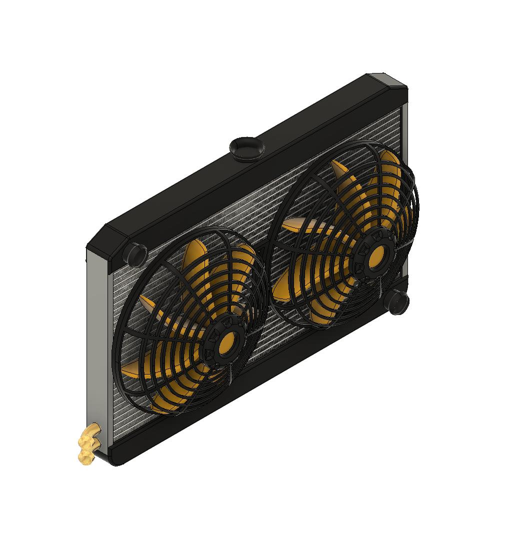

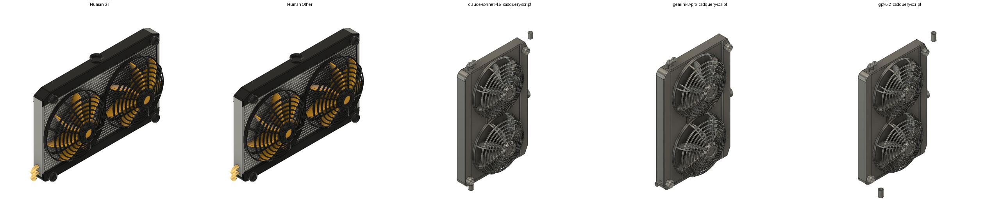

Request ID: SUJ2G2UMJQR7PMBX_1759203664.9815512
Edit ID: SUJ2G2UMJQR7PMBX_1759203978.2858508, User: SUJ2G2UMJQR7PMBX, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/SUJ2G2UMJQR7PMBX_1759204204.9140851_toprightiso.jpg
Edit ID: DYP2J9CYL7X46RLQ_1759986922.599179, User: DYP2J9CYL7X46RLQ, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/DYP2J9CYL7X46RLQ_1759987214.986006_toprightiso.jpg
Edit ID: gemini-3-pro_cadquery-script_1771009849.854084, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gemini-3-pro_cadquery-script_1771011065.7463481_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771011022.778857, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771012467.969682_topr

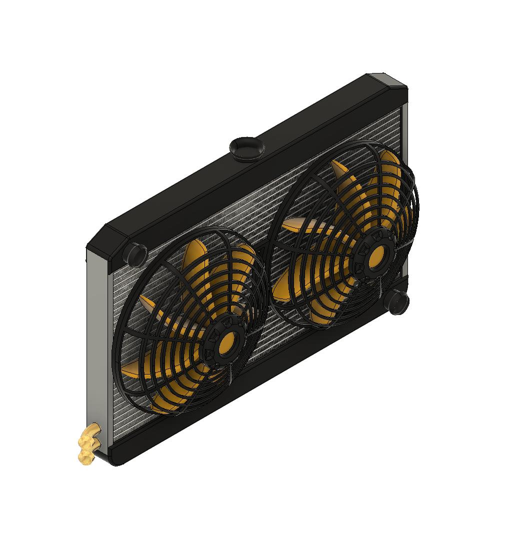

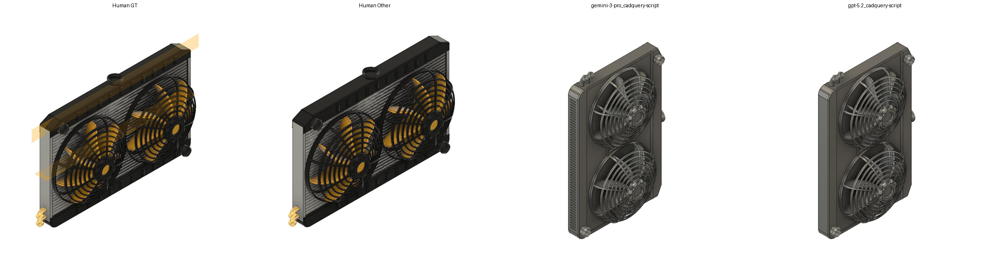

Request ID: SUJ2G2UMJQR7PMBX_1759203739.2515829
Edit ID: DYP2J9CYL7X46RLQ_1759904935.8686998, User: DYP2J9CYL7X46RLQ, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/DYP2J9CYL7X46RLQ_1759905802.985595_toprightiso.jpg
Edit ID: SUJ2G2UMJQR7PMBX_1759204645.96539, User: SUJ2G2UMJQR7PMBX, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/SUJ2G2UMJQR7PMBX_1759205119.859628_toprightiso.jpg
Edit ID: claude-sonnet-4.5_cadquery-script_1770986255.647797, User: claude-sonnet-4.5_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/claude-sonnet-4.5_cadquery-script_1770986565.34916_toprightiso.jpg
Edit ID: gemini-3-pro_cadquery-script_1771008739.732836, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gemini-3-pro_cadquery-scr

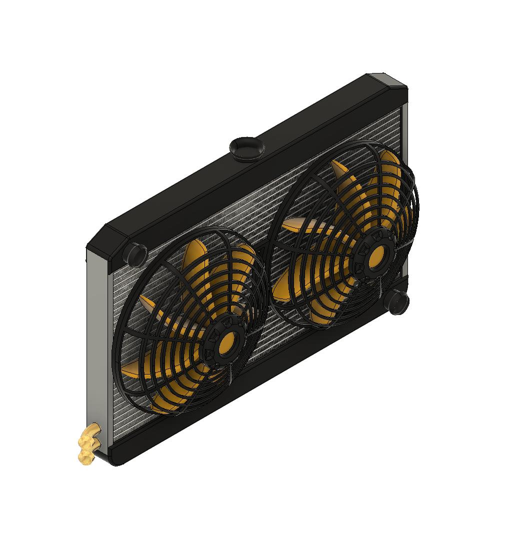

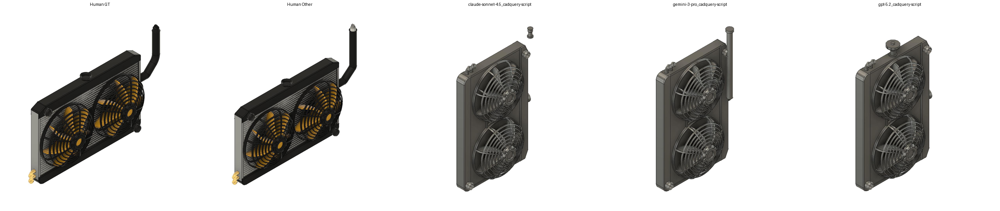

Request ID: SUJ2G2UMJQR7PMBX_1759209917.917027
Edit ID: SUJ2G2UMJQR7PMBX_1759210115.453844, User: SUJ2G2UMJQR7PMBX, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/SUJ2G2UMJQR7PMBX_1759210147.854375_toprightiso.jpg
Edit ID: DYP2J9CYL7X46RLQ_1759860084.3669388, User: DYP2J9CYL7X46RLQ, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/DYP2J9CYL7X46RLQ_1759860111.600329_toprightiso.jpg
Edit ID: gemini-3-pro_cadquery-script_1771002196.3418071, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gemini-3-pro_cadquery-script_1771003382.981604_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771003606.384844, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771004643.0194921_topri

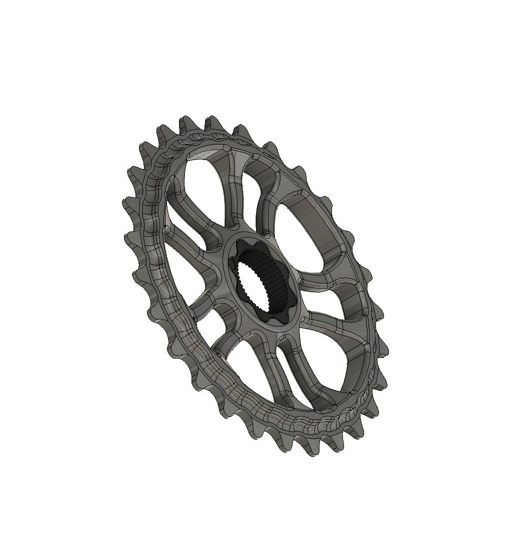

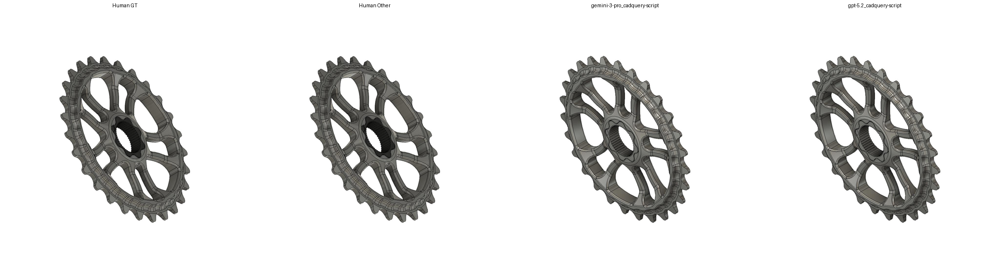

Request ID: SUJ2G2UMJQR7PMBX_1759209987.785593
Edit ID: SUJ2G2UMJQR7PMBX_1759210287.584769, User: SUJ2G2UMJQR7PMBX, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/SUJ2G2UMJQR7PMBX_1759210435.8404129_toprightiso.jpg
Edit ID: DYP2J9CYL7X46RLQ_1759860164.3991418, User: DYP2J9CYL7X46RLQ, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/DYP2J9CYL7X46RLQ_1759860375.806665_toprightiso.jpg
Edit ID: gemini-3-pro_cadquery-script_1771003853.8319528, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gemini-3-pro_cadquery-script_1771005086.4376981_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771005528.078835, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771006179.632007_topr

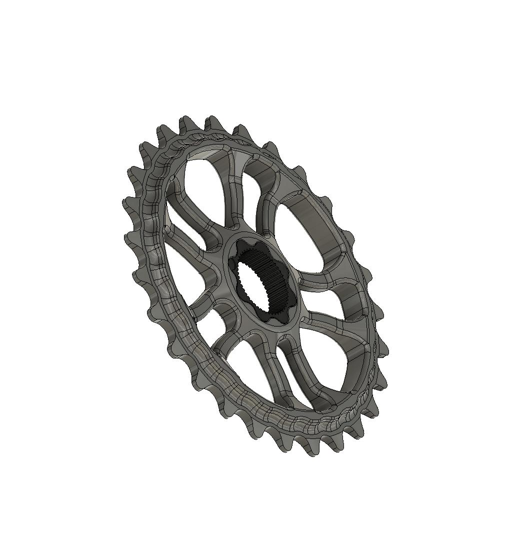

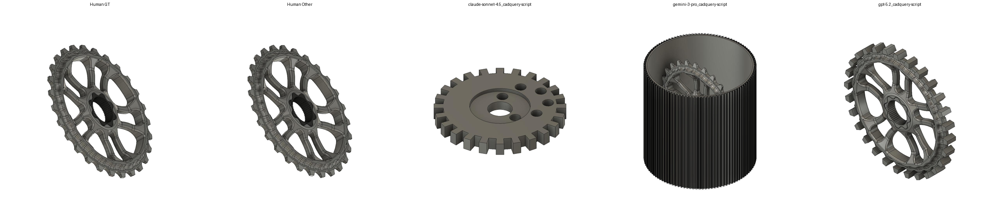

Request ID: SUJ2G2UMJQR7PMBX_1759210049.432666
Edit ID: DYP2J9CYL7X46RLQ_1759980289.423151, User: DYP2J9CYL7X46RLQ, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/DYP2J9CYL7X46RLQ_1759980572.150316_toprightiso.jpg
Edit ID: SUJ2G2UMJQR7PMBX_1759210766.720806, User: SUJ2G2UMJQR7PMBX, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/SUJ2G2UMJQR7PMBX_1759211057.193773_toprightiso.jpg
Edit ID: gemini-3-pro_cadquery-script_1771003382.982259, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gemini-3-pro_cadquery-script_1771003853.830362_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771004643.020728, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771005528.077374_topright

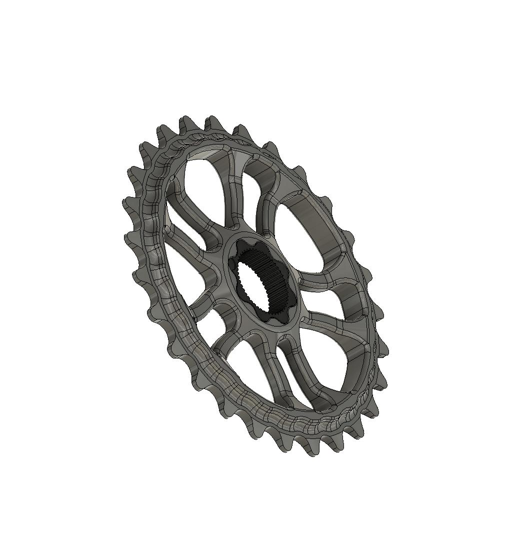

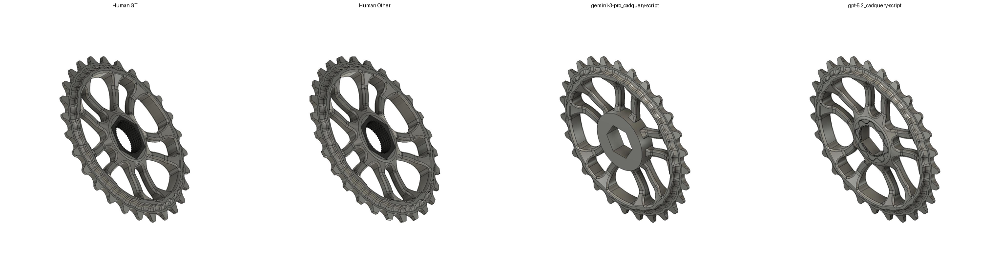

Request ID: ZK22J6VYRKQ2RTFD_1758873912.731081
Edit ID: ZK22J6VYRKQ2RTFD_1758874757.370628, User: ZK22J6VYRKQ2RTFD, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/ZK22J6VYRKQ2RTFD_1758874895.932203_toprightiso.jpg
Edit ID: 4E22SJE7QVTSP2E3_1759474358.243753, User: 4E22SJE7QVTSP2E3, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4E22SJE7QVTSP2E3_1759474488.95548_toprightiso.jpg
Edit ID: gemini-3-pro_cadquery-script_1771000466.597429, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gemini-3-pro_cadquery-script_1771002196.3410869_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771002669.7553349, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771003606.38405_topright

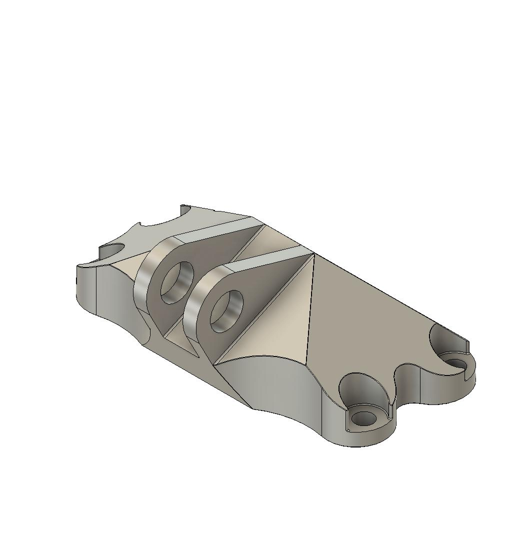

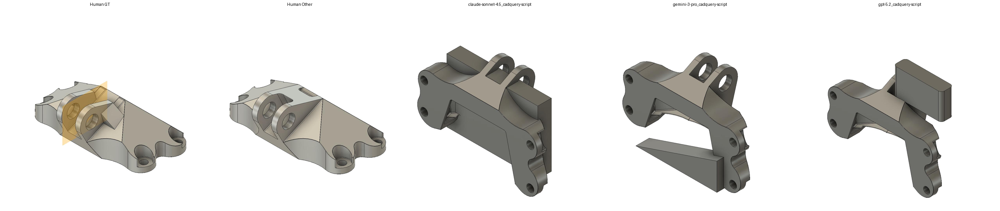

Request ID: ZK22J6VYRKQ2RTFD_1758874422.1403751
Edit ID: ZK22J6VYRKQ2RTFD_1758874931.490697, User: ZK22J6VYRKQ2RTFD, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/ZK22J6VYRKQ2RTFD_1758875051.4938471_toprightiso.jpg
Edit ID: 4E22SJE7QVTSP2E3_1759474640.0691998, User: 4E22SJE7QVTSP2E3, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4E22SJE7QVTSP2E3_1759474894.293233_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771001601.964771, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771002669.754448_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771439964.604213.
Edit ID: gemini-3-pro_cadquery-script_1771495233.7879932, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-A

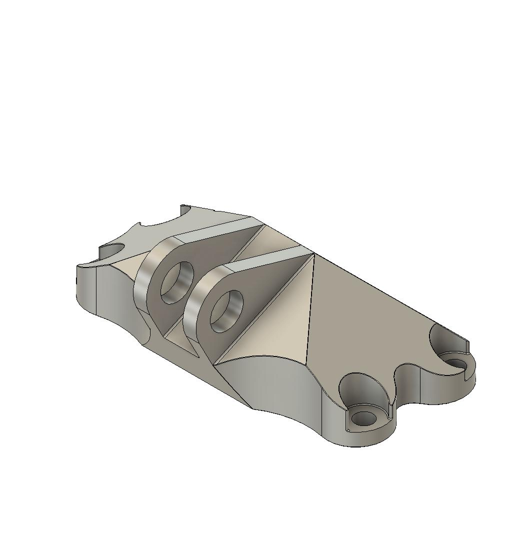

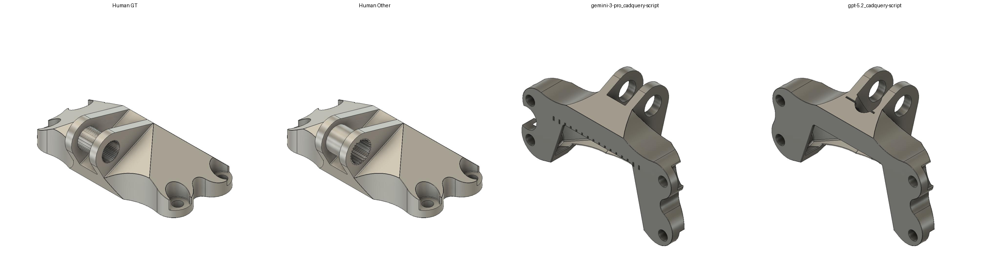

Request ID: ZK22J6VYRKQ2RTFD_1758875163.609787
Edit ID: ZK22J6VYRKQ2RTFD_1758872726.4214778, User: ZK22J6VYRKQ2RTFD, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/ZK22J6VYRKQ2RTFD_1758872753.6348438_toprightiso.jpg
Edit ID: 4E22SJE7QVTSP2E3_1759474163.355746, User: 4E22SJE7QVTSP2E3, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4E22SJE7QVTSP2E3_1759474204.136927_toprightiso.jpg
Edit ID: gemini-3-pro_cadquery-script_1770999571.203833, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gemini-3-pro_cadquery-script_1771000464.687089_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771001283.236814, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771001601.962851_toprig

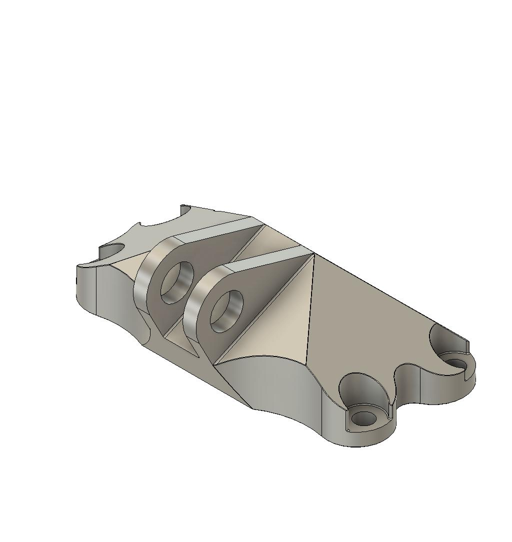

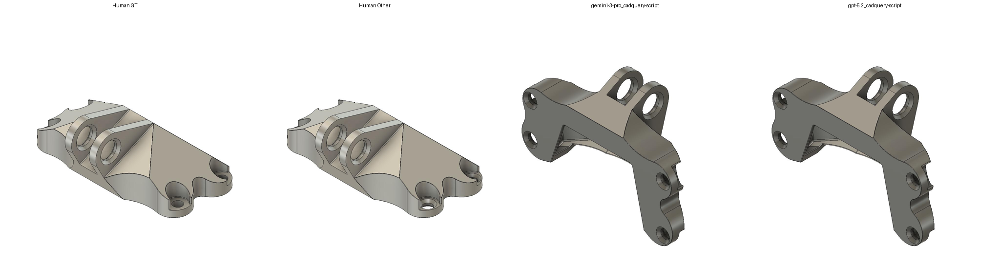

In [6]:
# Load request ids from the database (adjust the query to filter as needed)
request_query = {"request_type": "edit"}
request_ids = [request["_id"] for request in dbm.requests.find(request_query)]
request_ids.sort()
print(f"Found {len(request_ids)} requests")

models = [
    "Human GT",
    "Human Other",
    'gemini-3-pro_cadquery-script',
    "claude-sonnet-4.5_cadquery-script",
    "gpt-5.2_cadquery-script",
]

for request_id in request_ids:
    display_request_and_edits(dbm, request_id, output_dir=None, views=["dslrender","sketch", "render", "toprightiso"], n_horizontal=5, height=512, models=models)

Request ID: SUJ2G2UMJQR7PMBX_1759209987.785593
Edit ID: SUJ2G2UMJQR7PMBX_1759210287.584769, User: SUJ2G2UMJQR7PMBX, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/SUJ2G2UMJQR7PMBX_1759210435.8404129_toprightiso.jpg
Edit ID: DYP2J9CYL7X46RLQ_1759860164.3991418, User: DYP2J9CYL7X46RLQ, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/DYP2J9CYL7X46RLQ_1759860375.806665_toprightiso.jpg
Edit ID: gemini-3-pro_cadquery-script_1771003853.8319528, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gemini-3-pro_cadquery-script_1771005086.4376981_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771005528.078835, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771006179.632007_topr

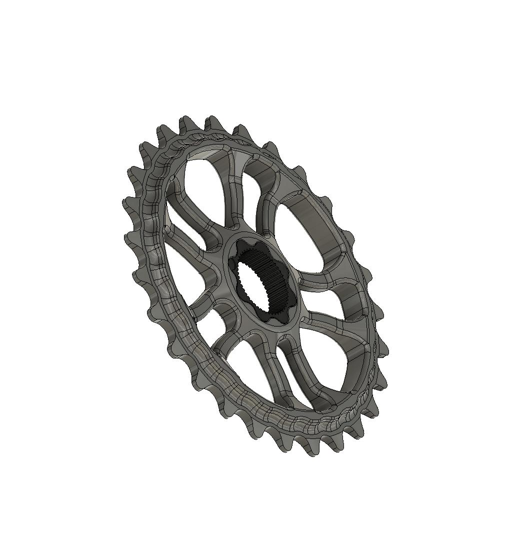

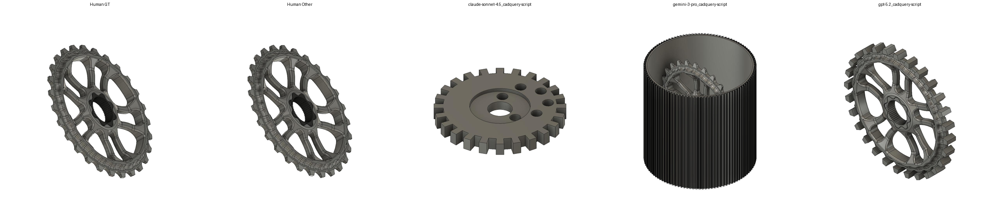

Request ID: 3YH2WFSRM22W7DKT_1769773335.525203
Edit ID: DYP2J9CYL7X46RLQ_1770186958.083383, User: DYP2J9CYL7X46RLQ, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/DYP2J9CYL7X46RLQ_1770187029.628212_toprightiso.jpg
Edit ID: 3YH2WFSRM22W7DKT_1769776718.7657201, User: 3YH2WFSRM22W7DKT, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/3YH2WFSRM22W7DKT_1769776990.4257011_toprightiso.jpg
Edit ID: claude-sonnet-4.5_cadquery-script_1771043329.849885, User: claude-sonnet-4.5_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/claude-sonnet-4.5_cadquery-script_1771043690.891785_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771173598.737011, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_177117381

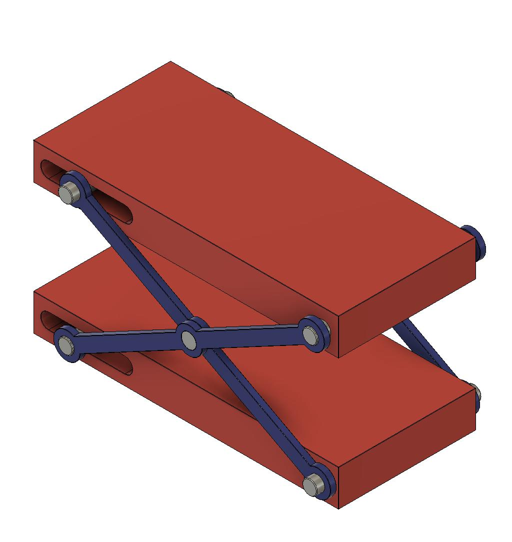

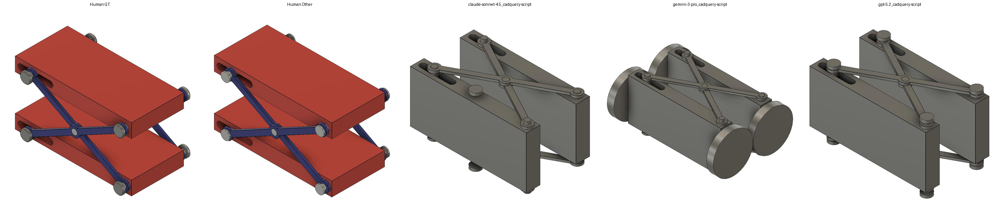

Request ID: B7A2N74ZJBF9MZHU_1770174133.012106
Edit ID: B7A2N74ZJBF9MZHU_1770174206.720026, User: B7A2N74ZJBF9MZHU, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/B7A2N74ZJBF9MZHU_1770174221.1854131_toprightiso.jpg
Edit ID: SUJ2G2UMJQR7PMBX_1770271720.736626, User: SUJ2G2UMJQR7PMBX, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/SUJ2G2UMJQR7PMBX_1770271748.8171039_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771090260.778689, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771091674.9915452_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771461968.0479648.
Edit ID: gemini-3-pro_cadquery-script_1771465920.4619389, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-

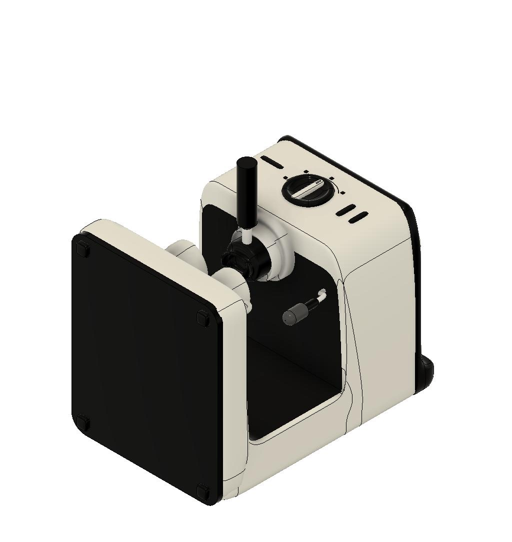

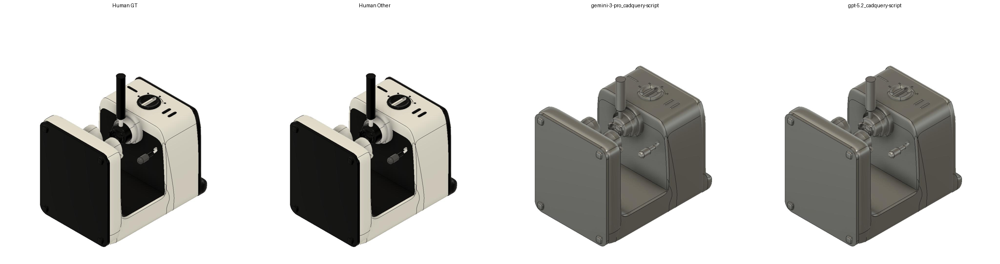

Request ID: F332D3FXML85WLR2_1769607142.566352
Edit ID: F332D3FXML85WLR2_1769607294.73713, User: F332D3FXML85WLR2, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/F332D3FXML85WLR2_1769608193.091736_toprightiso.jpg
Edit ID: DYP2J9CYL7X46RLQ_1770263941.737219, User: DYP2J9CYL7X46RLQ, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/DYP2J9CYL7X46RLQ_1770264376.3208_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771086666.681466, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771089547.5143418_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771585971.711572.
Edit ID: gemini-3-pro_cadquery-script_1771464028.950561, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodes

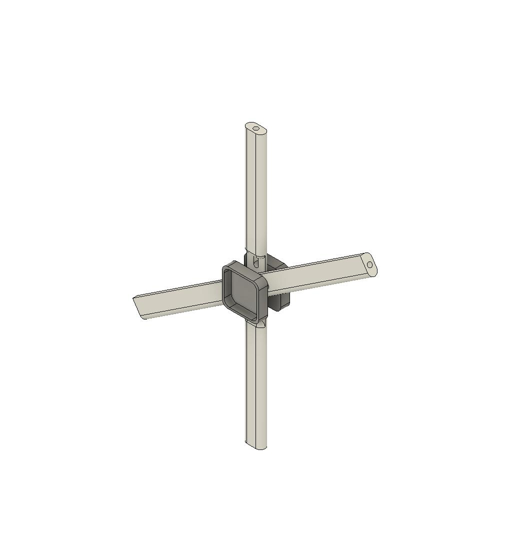

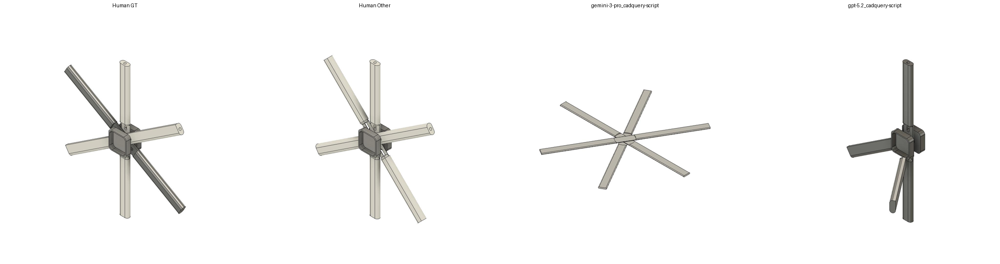

Request ID: ZK22J6VYRKQ2RTFD_1758874422.1403751
Edit ID: ZK22J6VYRKQ2RTFD_1758874931.490697, User: ZK22J6VYRKQ2RTFD, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/ZK22J6VYRKQ2RTFD_1758875051.4938471_toprightiso.jpg
Edit ID: 4E22SJE7QVTSP2E3_1759474640.0691998, User: 4E22SJE7QVTSP2E3, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/4E22SJE7QVTSP2E3_1759474894.293233_toprightiso.jpg
Edit ID: gpt-5.2_cadquery-script_1771001601.964771, User: gpt-5.2_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-Autodesk-neuralCAD-Edit\data\edit_192_external\breps/gpt-5.2_cadquery-script_1771002669.754448_toprightiso.jpg
No images found for format ['jpg', 'png'] in brep claude-sonnet-4.5_cadquery-script_1771439964.604213.
Edit ID: gemini-3-pro_cadquery-script_1771495233.7879932, User: gemini-3-pro_cadquery-script, BRep Image: C:\Users\schae\Desktop\IDETC26-Hackathon-A

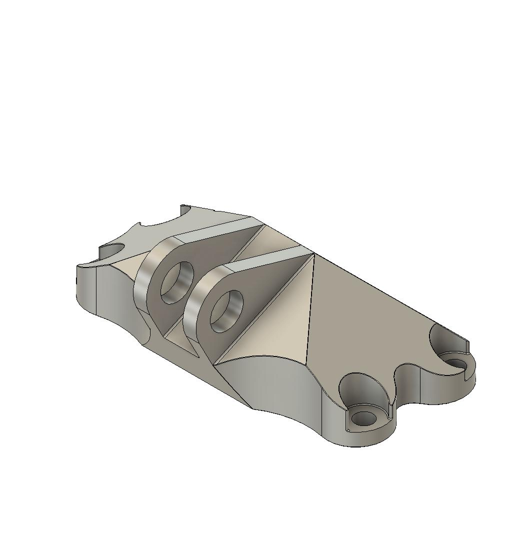

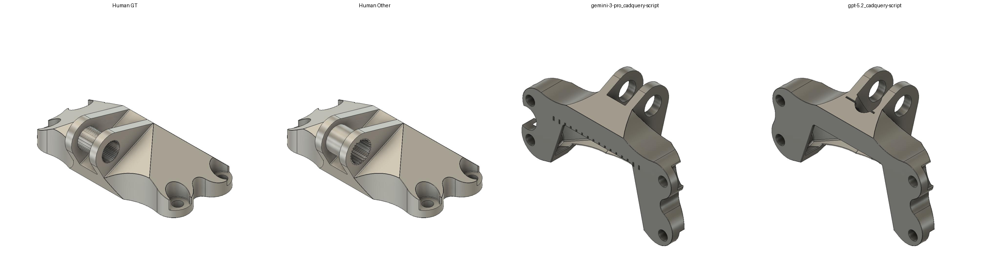

In [7]:
# Test requests.

request_ids = ['SUJ2G2UMJQR7PMBX_1759209987.785593',
'3YH2WFSRM22W7DKT_1769773335.525203',
'B7A2N74ZJBF9MZHU_1770174133.012106',
'F332D3FXML85WLR2_1769607142.566352',
'ZK22J6VYRKQ2RTFD_1758874422.1403751',
]

models = [
    "Human GT",
    "Human Other",
    'gemini-3-pro_cadquery-script',
    "claude-sonnet-4.5_cadquery-script",
    "gpt-5.2_cadquery-script",
]

for request_id in request_ids:
    display_request_and_edits(dbm, request_id, output_dir=None, views=["dslrender","sketch", "render", "toprightiso"], n_horizontal=5, height=512, models=models)